# Machine Learning Lab: Chlorophyll-a Forecasting

**Objective:** Predict the daily concentration of Chlorophyll-a (`chlorophyll_a_mg_m3`) using historical environmental data. 
This notebook documents the full evolutionary process of our modeling pipeline, starting from raw data exploration, identifying pipeline vulnerabilities (like outliers and skewness), testing feature engineering hypotheses, and culminating in our final Lasso-Ridge architecture.

In [62]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import itertools
from scipy.stats import zscore
from sklearn.preprocessing import StandardScaler
from sklearn import linear_model
from sklearn.metrics import r2_score, mean_absolute_error

import warnings
warnings.filterwarnings('ignore')

## 1. Initial Data Exploration: Exogenous Features vs. Target

In order to define how many time-series lags each variable should be given, we need to understand  relationship between our exogenous environmental variables and the target variable (`chlorophyll_a_mg_m3`). 

Visualizing these relationships helps identify non-linearities, heteroscedasticity, and extreme outliers that might destabilize linear models later on.

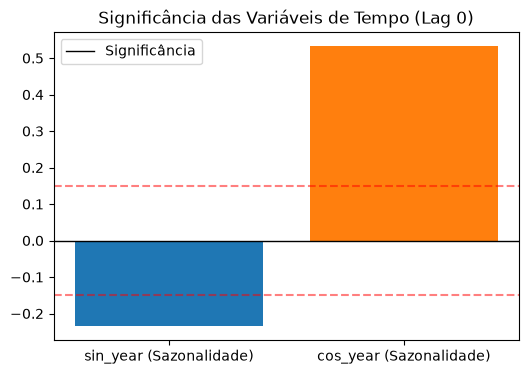

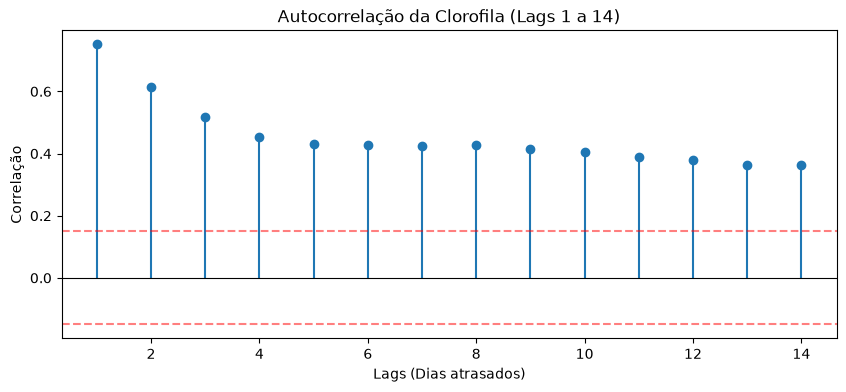

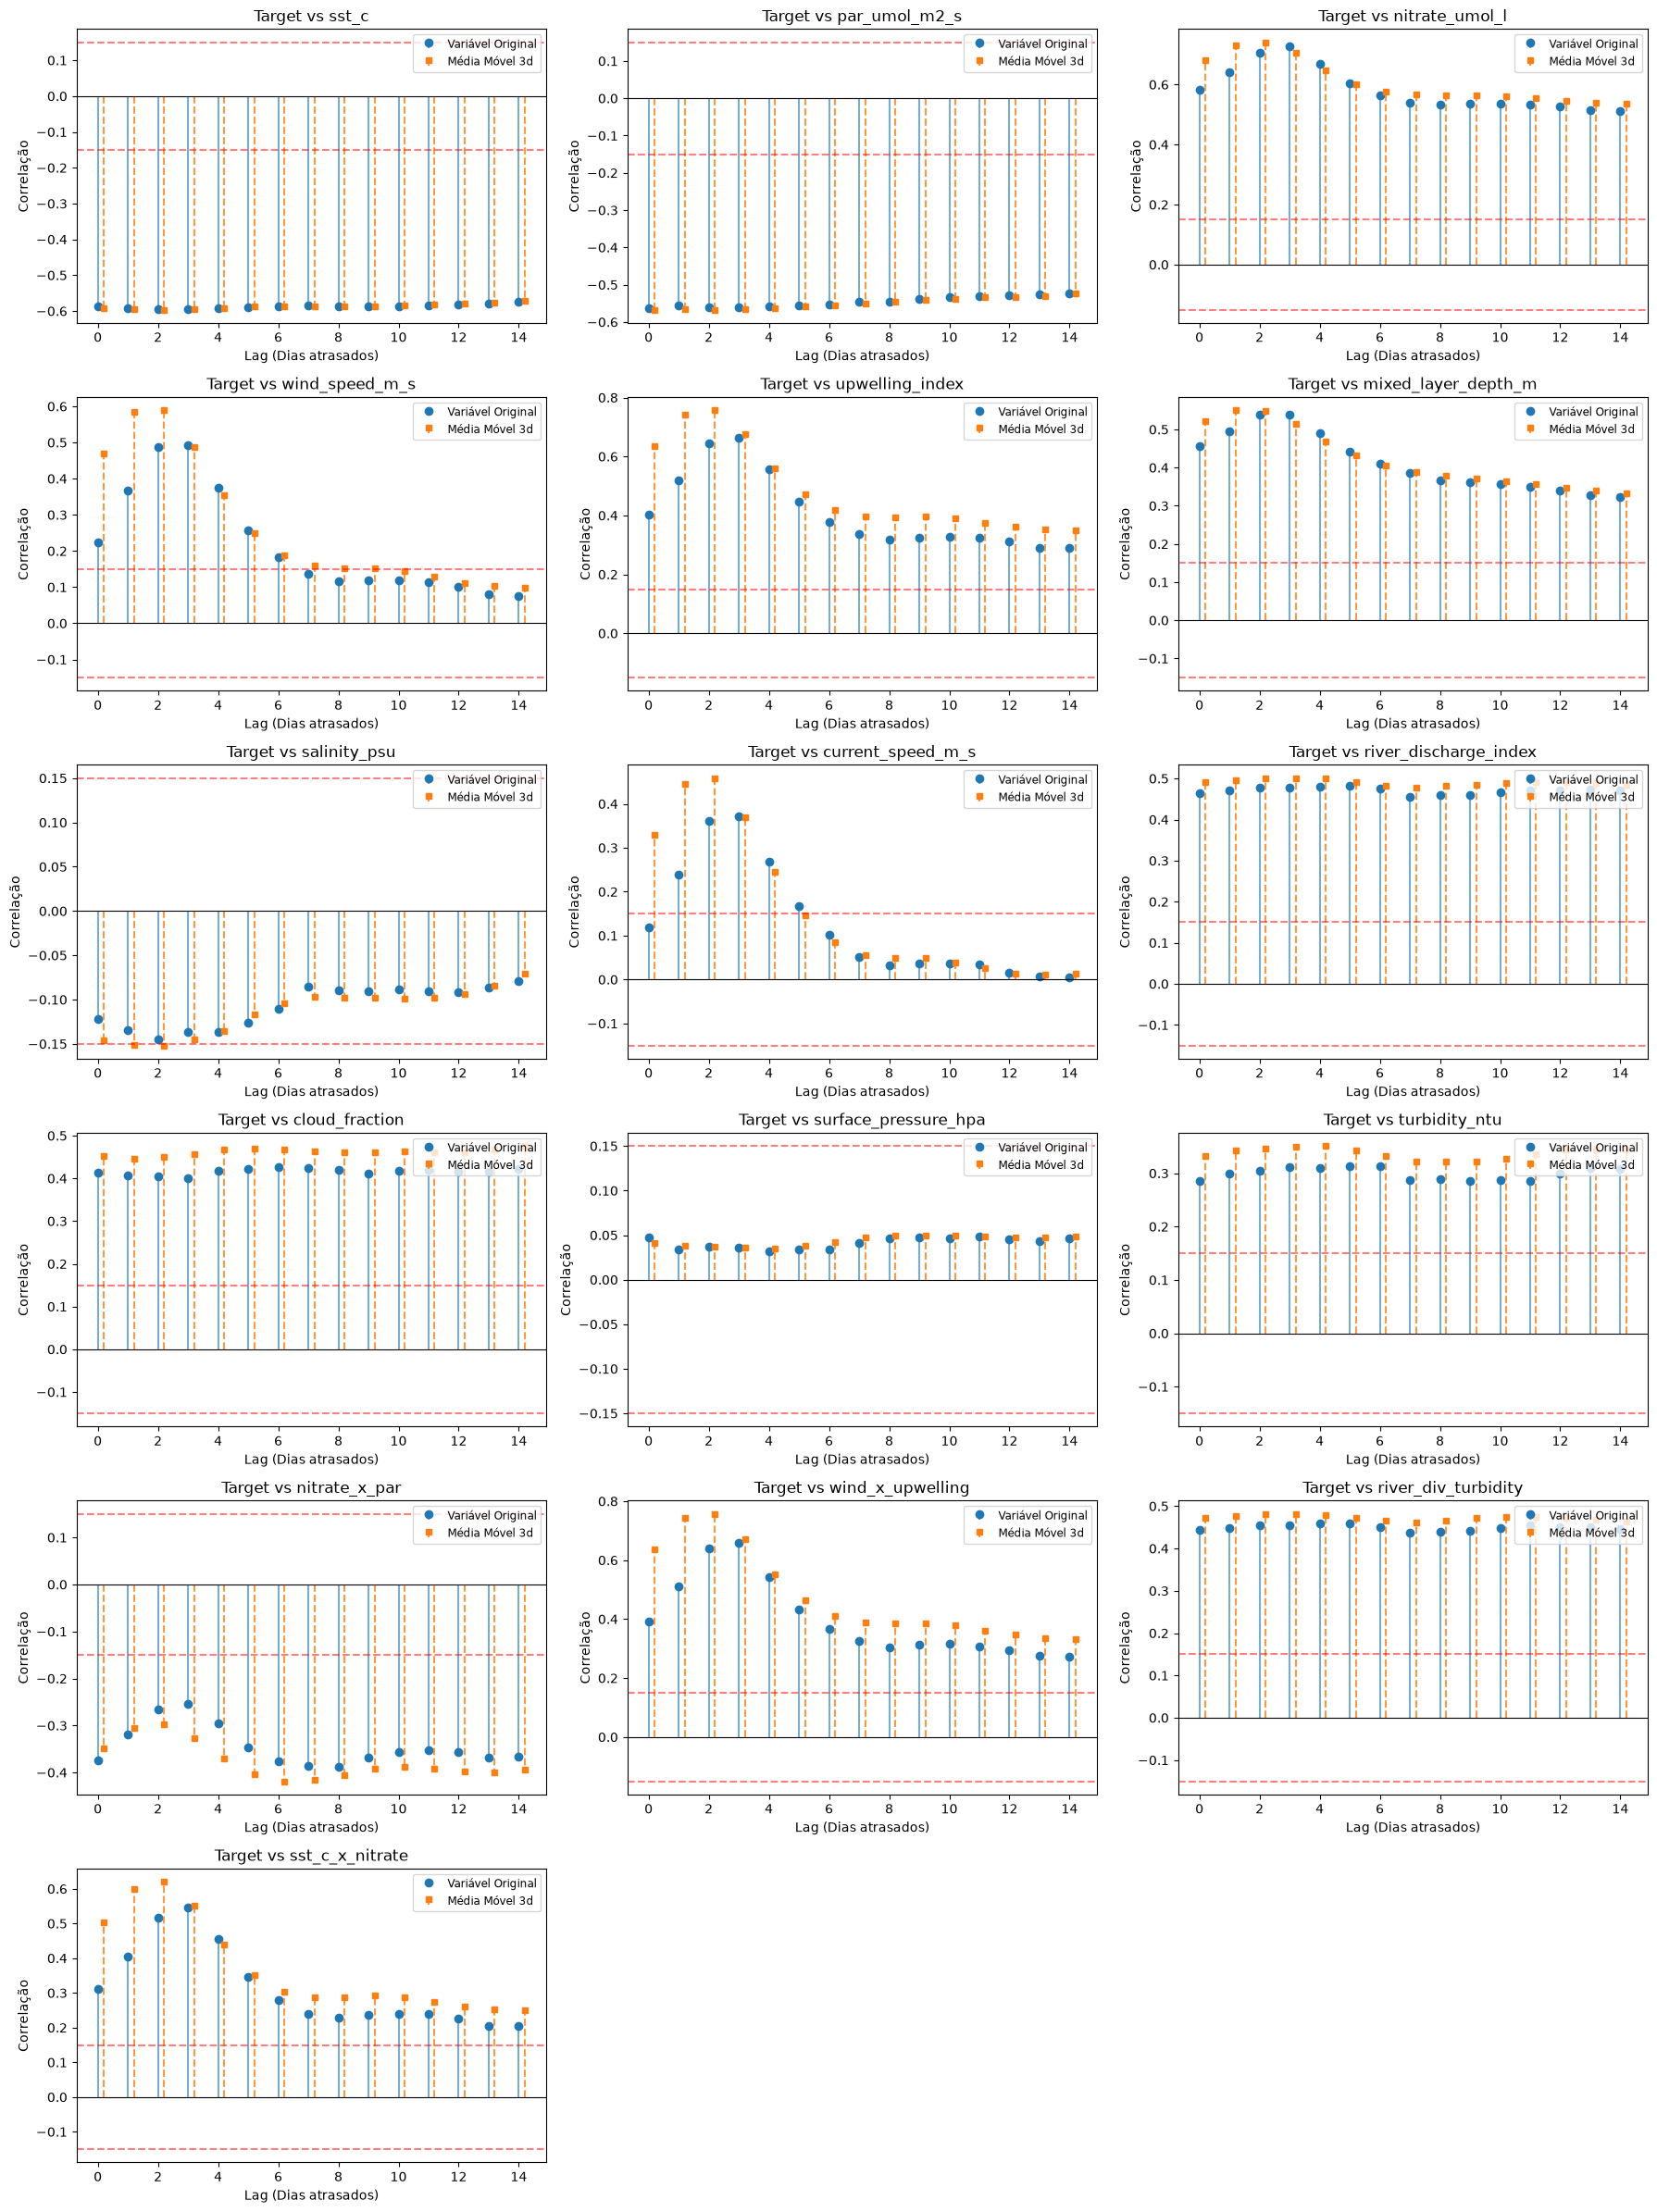

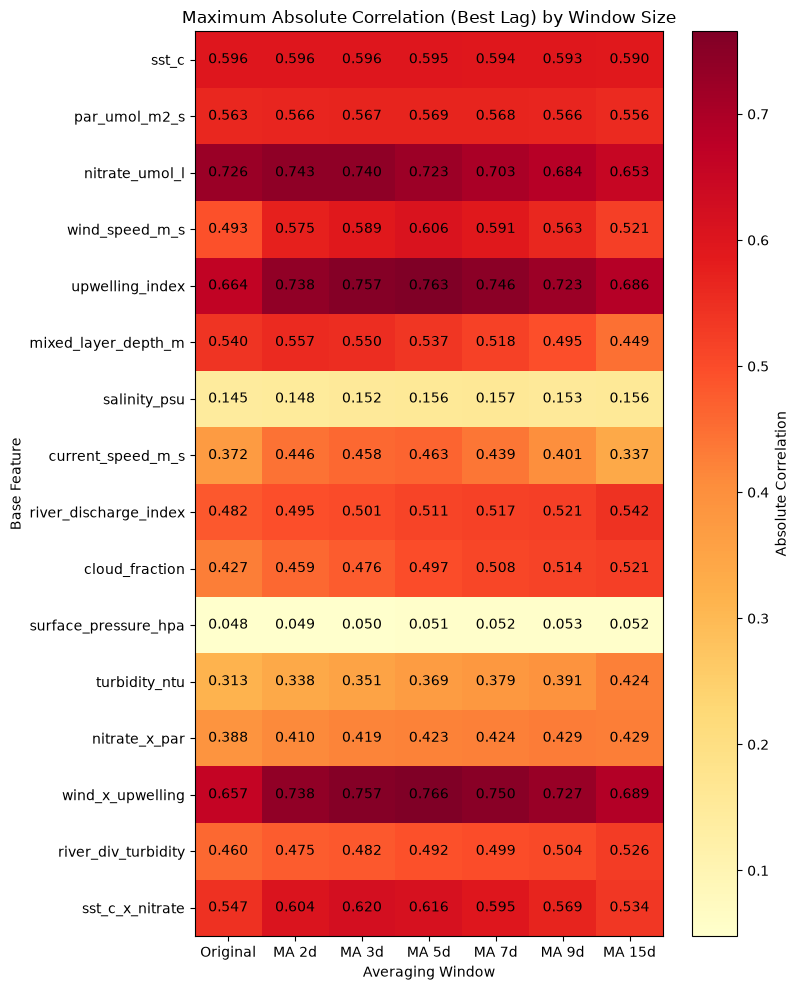

In [80]:
# Load raw data without any transformations
df_raw = pd.read_excel("../../data/chlorophyll_student_2015_2023.xlsx", sheet_name="daily_data")
df_raw["date"] = pd.to_datetime(df_raw["date"])
df_raw = df_raw.sort_values("date").reset_index(drop=True)



# Adding new columns that relate variables 
scaler = StandardScaler()
df_raw["nitrate_x_par"] = df_raw["nitrate_umol_l"] * df_raw["par_umol_m2_s"]
df_raw["wind_x_upwelling"] = df_raw["wind_speed_m_s"] * df_raw["upwelling_index"]
df_raw["river_div_turbidity"] = df_raw["river_discharge_index"] / (df_raw["turbidity_ntu"] + 1)
df_raw["sst_c_x_nitrate"] = df_raw["sst_c"] * df_raw["nitrate_umol_l"]

# Listing only the columns to which a Moving Average will be aplied 
window_sizes = [2, 3, 5, 7, 9, 15]
exogenous_cols_mv = df_raw.drop(columns=["date", "chlorophyll_a_mg_m3"]).columns
conf_level = 0.15

# GENERATE ALL MOVING AVERAGES HERE
for window in window_sizes:
    for feature in exogenous_cols_mv:
        df_raw[f"{feature}_average_{window}"] = df_raw[feature].rolling(window=window, min_periods=1).mean()

cols_to_scale = df_raw.columns.drop("date")
df_raw[cols_to_scale] = scaler.fit_transform(df_raw[cols_to_scale])

day_of_year = df_raw["date"].dt.dayofyear

# Apply the trigonometric formulas for seasonality
df_raw["sin_year"] = np.sin(2 * np.pi * day_of_year / 365.25)
df_raw["cos_year"] = np.cos(2 * np.pi * day_of_year / 365.25)

# Calculate their direct significance (Pearson correlation)
corr_sin = df_raw["chlorophyll_a_mg_m3"].corr(df_raw["sin_year"])
corr_cos = df_raw["chlorophyll_a_mg_m3"].corr(df_raw["cos_year"])

# Plot the significance statically
plt.figure(figsize=(6, 4))
plt.bar(["sin_year (Sazonalidade)", "cos_year (Sazonalidade)"], [corr_sin, corr_cos], color=['tab:blue', 'tab:orange'])
plt.axhline(0, color='black', linewidth=1)
plt.axhline(conf_level, color='red', linestyle='--', alpha=0.5)
plt.axhline(-conf_level, color='red', linestyle='--', alpha=0.5)
plt.title("Significância das Variáveis de Tempo (Lag 0)")
plt.legend(["Significância"])
plt.show()

target_col = "chlorophyll_a_mg_m3"
max_lags = 15

# Autocorrelação da Clorofila
acf_values = [df_raw[target_col].corr(df_raw[target_col].shift(lag)) for lag in range(1, max_lags)]

plt.figure(figsize=(10, 4))
plt.stem(range(1, max_lags), acf_values, basefmt=" ")
plt.axhline(0, color='black', linewidth=0.8)
plt.axhline(conf_level, color='red', linestyle='--', alpha=0.5)
plt.axhline(-conf_level, color='red', linestyle='--', alpha=0.5)
plt.title(f"Autocorrelação da Clorofila (Lags 1 a {max_lags-1})")
plt.xlabel("Lags (Dias atrasados)")
plt.ylabel("Correlação")
plt.show()

# Isolar as variáveis originais e as interações (ignorando todas as médias móveis e variáveis de tempo)
base_features = [col for col in df_raw.columns if "_average_" not in col and col not in ["date", target_col, "sin_year", "cos_year"]]

num_features = len(base_features)
num_cols = 3
num_rows = (num_features + num_cols - 1) // num_cols 

plt.figure(figsize=(18, 4 * num_rows))

for i, feature in enumerate(base_features, 1):
    plt.subplot(num_rows, num_cols, i)
    
    # Original feature correlation
    ccf_values_raw = [df_raw[target_col].corr(df_raw[feature].shift(lag)) for lag in range(0, max_lags)]
    lags_raw = np.arange(0, max_lags)
    
    # Plotting raw variable (Blue Circles)
    markerline1, stemlines1, baseline1 = plt.stem(lags_raw, ccf_values_raw, basefmt=" ", label="Variável Original")
    plt.setp(markerline1, color='tab:blue', markersize=6)
    plt.setp(stemlines1, color='tab:blue', alpha=0.6)
    
    # FILTER TO ONLY PLOT THE 3-DAY AVERAGE ON THE STEM PLOTS
    avg_feature = f"{feature}_average_3"
    if avg_feature in df_raw.columns:
        ccf_values_avg = [df_raw[target_col].corr(df_raw[avg_feature].shift(lag)) for lag in range(0, max_lags)]
        
        # Offset the x-axis slightly by 0.2 so the lines do not overlap
        lags_avg = np.arange(0, max_lags) + 0.2 
        
        # Plotting averaged variable (Orange Squares)
        markerline2, stemlines2, baseline2 = plt.stem(lags_avg, ccf_values_avg, basefmt=" ", label="Média Móvel 3d")
        plt.setp(markerline2, color='tab:orange', markersize=5, marker='s')
        plt.setp(stemlines2, color='tab:orange', linestyle='--', alpha=0.8)

    plt.axhline(0, color='black', linewidth=0.8)
    plt.axhline(conf_level, color='red', linestyle='--', alpha=0.5)
    plt.axhline(-conf_level, color='red', linestyle='--', alpha=0.5)
    
    plt.title(f"Target vs {feature}")
    plt.xlabel("Lag (Dias atrasados)")
    plt.ylabel("Correlação")
    plt.legend(loc="upper right", fontsize='small')

plt.tight_layout()
plt.show()


heatmap_data = []
column_labels = ["Original"] + [f"MA {w}d" for w in window_sizes]

for feature in base_features:
    # Find the maximum absolute correlation for the original variable across all lags
    corrs_raw = [df_raw[target_col].corr(df_raw[feature].shift(lag)) for lag in range(0, max_lags)]
    max_raw = max(corrs_raw, key=abs)
    
    row_data = [abs(max_raw)]
    
    # Find the maximum absolute correlation for ALL moving average windows
    for window in window_sizes:
        avg_feature = f"{feature}_average_{window}"
        if avg_feature in df_raw.columns:
            corrs_avg = [df_raw[target_col].corr(df_raw[avg_feature].shift(lag)) for lag in range(0, max_lags)]
            max_avg = max(corrs_avg, key=abs)
            row_data.append(abs(max_avg))
        else:
            row_data.append(0.0) # Fallback if missing
            
    heatmap_data.append(row_data)

# Convert to a 2D numpy array for matplotlib
heatmap_array = np.array(heatmap_data)

# Plotting the heatmap natively in Matplotlib
fig, ax = plt.subplots(figsize=(8, 10))
cax = ax.imshow(heatmap_array, cmap="YlOrRd", aspect="auto")

# Configure the axes ticks and labels
ax.set_xticks(np.arange(len(column_labels)))
ax.set_yticks(np.arange(len(base_features)))
ax.set_xticklabels(column_labels)
ax.set_yticklabels(base_features)

# Loop over the data and overlay the exact correlation numbers on the colored squares
for i in range(len(base_features)):
    for j in range(len(column_labels)):
        ax.text(j, i, f"{heatmap_array[i, j]:.3f}", ha="center", va="center", color="black")

plt.title("Maximum Absolute Correlation (Best Lag) by Window Size")
plt.xlabel("Averaging Window")
plt.ylabel("Base Feature")
plt.colorbar(cax, label="Absolute Correlation")
plt.tight_layout()
plt.show()

## 2. Base Preprocessing and Initial Observations

Our baseline approach involves generating historical lag features (1-15 days for the target, 0-15 days for exogenous variables) and encoding the day of the year cyclically. 

In this initial phase, we scale the data but **do not** apply target transformations or outlier smoothing. This establishes a baseline to measure future pipeline improvements against.

In [64]:
from build_lagged_features import build_lagged_frame

DATE = "date"
TARGET = "chlorophyll_a_mg_m3"

defined_lags = {
    TARGET: list(range(1, 15)),
    "sst_c": list(range(0, 15)),
    "par_umol_m2_s": list(range(0, 15)),
    "nitrate_umol_l": list(range(0, 15)),
    "wind_speed_m_s": list(range(0, 15)),
    "upwelling_index": list(range(0, 15)),
    "mixed_layer_depth_m": list(range(0, 15)),
    "salinity_psu": list(range(0, 15)),
    "current_speed_m_s": list(range(0, 15)),
    "river_discharge_index": list(range(0, 15)),
    "cloud_fraction": list(range(0, 15)),
    "surface_pressure_hpa": list(range(0, 15)),
    "turbidity_ntu": list(range(0, 15)),
}

# Build baseline features using the imported function
df_baseline = build_lagged_frame(df_raw, lag_spec=defined_lags)

# Chronological split (Train, Validation, Test)
lower_sep = -2*365
higher_sep = -365

X_base = df_baseline.drop(columns=[DATE, TARGET])
Y_base = df_baseline[TARGET]

X_train_base = X_base.iloc[:lower_sep]
X_val_base = X_base.iloc[lower_sep:higher_sep]
X_test_base = X_base.iloc[higher_sep:]

Y_train_base = Y_base.iloc[:lower_sep]
Y_val_base = Y_base.iloc[lower_sep:higher_sep]
Y_test_base = Y_base.iloc[higher_sep:]

# Baseline Scaling
scaler_base = StandardScaler()
X_train_scaled_base = pd.DataFrame(scaler_base.fit_transform(X_train_base), columns=X_train_base.columns)
X_val_scaled_base = pd.DataFrame(scaler_base.transform(X_val_base), columns=X_val_base.columns)
X_test_scaled_base = pd.DataFrame(scaler_base.transform(X_test_base), columns=X_test_base.columns)

# Baseline Lasso Fit
baseline_lasso = linear_model.Lasso(alpha=0.01, max_iter=10000)
baseline_lasso.fit(X_train_scaled_base, Y_train_base)

baseline_val_preds = baseline_lasso.predict(X_val_scaled_base)
baseline_test_preds = baseline_lasso.predict(X_test_scaled_base)

print(f"Baseline Validation R^2: {r2_score(Y_val_base, baseline_val_preds):.4f}")
print(f"Baseline Validation MAE: {mean_absolute_error(Y_val_base, baseline_val_preds):.4f}")
print(f"Baseline Test R^2: {r2_score(Y_test_base, baseline_test_preds):.4f}")
print(f"Baseline Test MAE: {mean_absolute_error(Y_test_base, baseline_test_preds):.4f}")

Baseline Validation R^2: 0.8326
Baseline Validation MAE: 0.2713
Baseline Test R^2: 0.5129
Baseline Test MAE: 0.3451


### 2.1 The Danger of Data Leakage: 2-Way vs. 3-Way Splits

A common pitfall in machine learning is using a simple 2-way split (Train/Test) and tuning hyperparameters directly on the test set. This leaks information about the unseen future data into the model configuration, resulting in an artificially inflated performance metric that will not hold up when testing with new data.

Furthermore, tuning on the Test set causes the model to select a different underlying architecture (in Lasso's case, the number of retained features). It will adjust its sparsity to artificially "fit" the noise in the Test set, completely changing which environmental variables are deemed important.

To demonstrate this, we will compare two approaches while keeping the training data strictly identical:
1. **Flawed 2-Way Split:** We train on the Train set, but pick the best `alpha` by checking which one scores highest directly on the Test set.
2. **Proper 3-Way Split:** We train on the Train set, pick the best `alpha` using the Validation set, and then test *only once* on the Test set to get an honest metric.

In [65]:
alphas_to_test = [1.0, 0.5, 0.1, 0.05, 0.01, 0.005, 0.001]

print("--- Flawed 2-Way Split (Tuning on Test Set) ---")
best_test_r2_flawed = -float('inf')
best_alpha_flawed = None
flawed_features_kept = 0

for alpha in alphas_to_test:
    flawed_model = linear_model.Lasso(alpha=alpha, max_iter=10000)
    flawed_model.fit(X_train_scaled_base, Y_train_base)
    
    # DATA LEAKAGE: Peeking at the Test set during the tuning loop!
    test_preds_flawed = flawed_model.predict(X_test_scaled_base)
    test_r2_flawed = r2_score(Y_test_base, test_preds_flawed)
    
    if test_r2_flawed > best_test_r2_flawed:
        best_test_r2_flawed = test_r2_flawed
        best_alpha_flawed = alpha
        flawed_features_kept = np.sum(flawed_model.coef_ != 0)

print(f"Chosen Alpha: {best_alpha_flawed}")
print(f"Features Kept by Model: {flawed_features_kept} ")
print(f"Reported Test R^2: {best_test_r2_flawed:.4f} \n")


print("--- Proper 3-Way Split (Tuning on Validation Set) ---")
best_val_r2_proper = -float('inf')
best_alpha_proper = None

# Step 1 & 2: Train and Tune using strictly Train/Val splits
for alpha in alphas_to_test:
    proper_model = linear_model.Lasso(alpha=alpha, max_iter=10000)
    proper_model.fit(X_train_scaled_base, Y_train_base)
    
    # NO LEAKAGE: Using the Validation set to make decisions
    val_preds_proper = proper_model.predict(X_val_scaled_base)
    val_r2_proper = r2_score(Y_val_base, val_preds_proper)
    
    if val_r2_proper > best_val_r2_proper:
        best_val_r2_proper = val_r2_proper
        best_alpha_proper = alpha

# Step 3: Test exactly once using the chosen alpha
final_proper_model = linear_model.Lasso(alpha=best_alpha_proper, max_iter=10000)
final_proper_model.fit(X_train_scaled_base, Y_train_base)
proper_test_preds = final_proper_model.predict(X_test_scaled_base)
proper_test_r2 = r2_score(Y_test_base, proper_test_preds)
proper_features_kept = np.sum(final_proper_model.coef_ != 0)

print(f"Chosen Alpha: {best_alpha_proper}")
print(f"Features Kept by Model: {proper_features_kept} ")
print(f"True Unbiased Test R^2: {proper_test_r2:.4f}")
print(f"\nGap in reported performance: {(best_test_r2_flawed - proper_test_r2):.4f}")

--- Flawed 2-Way Split (Tuning on Test Set) ---
Chosen Alpha: 0.005
Features Kept by Model: 56 
Reported Test R^2: 0.5140 

--- Proper 3-Way Split (Tuning on Validation Set) ---
Chosen Alpha: 0.05
Features Kept by Model: 10 
True Unbiased Test R^2: 0.5018

Gap in reported performance: 0.0123


This results show that, in order to obtain better results in the test split, the 2-Way-Split chose `alpha` = 0.005. This will lead to an overfit of the test data, and adopting a policy of maximizing R^2 based in this should not be done. With the 3-Way-Split, since there is a middle set for validation, with respect to who the optimization of the hyperparameters is done, the test data is only use for a real evaluation. This approach is closer to the evaluation procedure that we will face.

## 3. Preprocessing Study
When analysing the given data, we saw that all of them contain outliers, from `chlorophyll_a_mg_m3` to the exogenous variables. The laboratory guide mentions that some sensors are subjected to noise and some measurements do not reflect the reality. In order to see the scale of this outliers, the various variables were plotted as a function of time



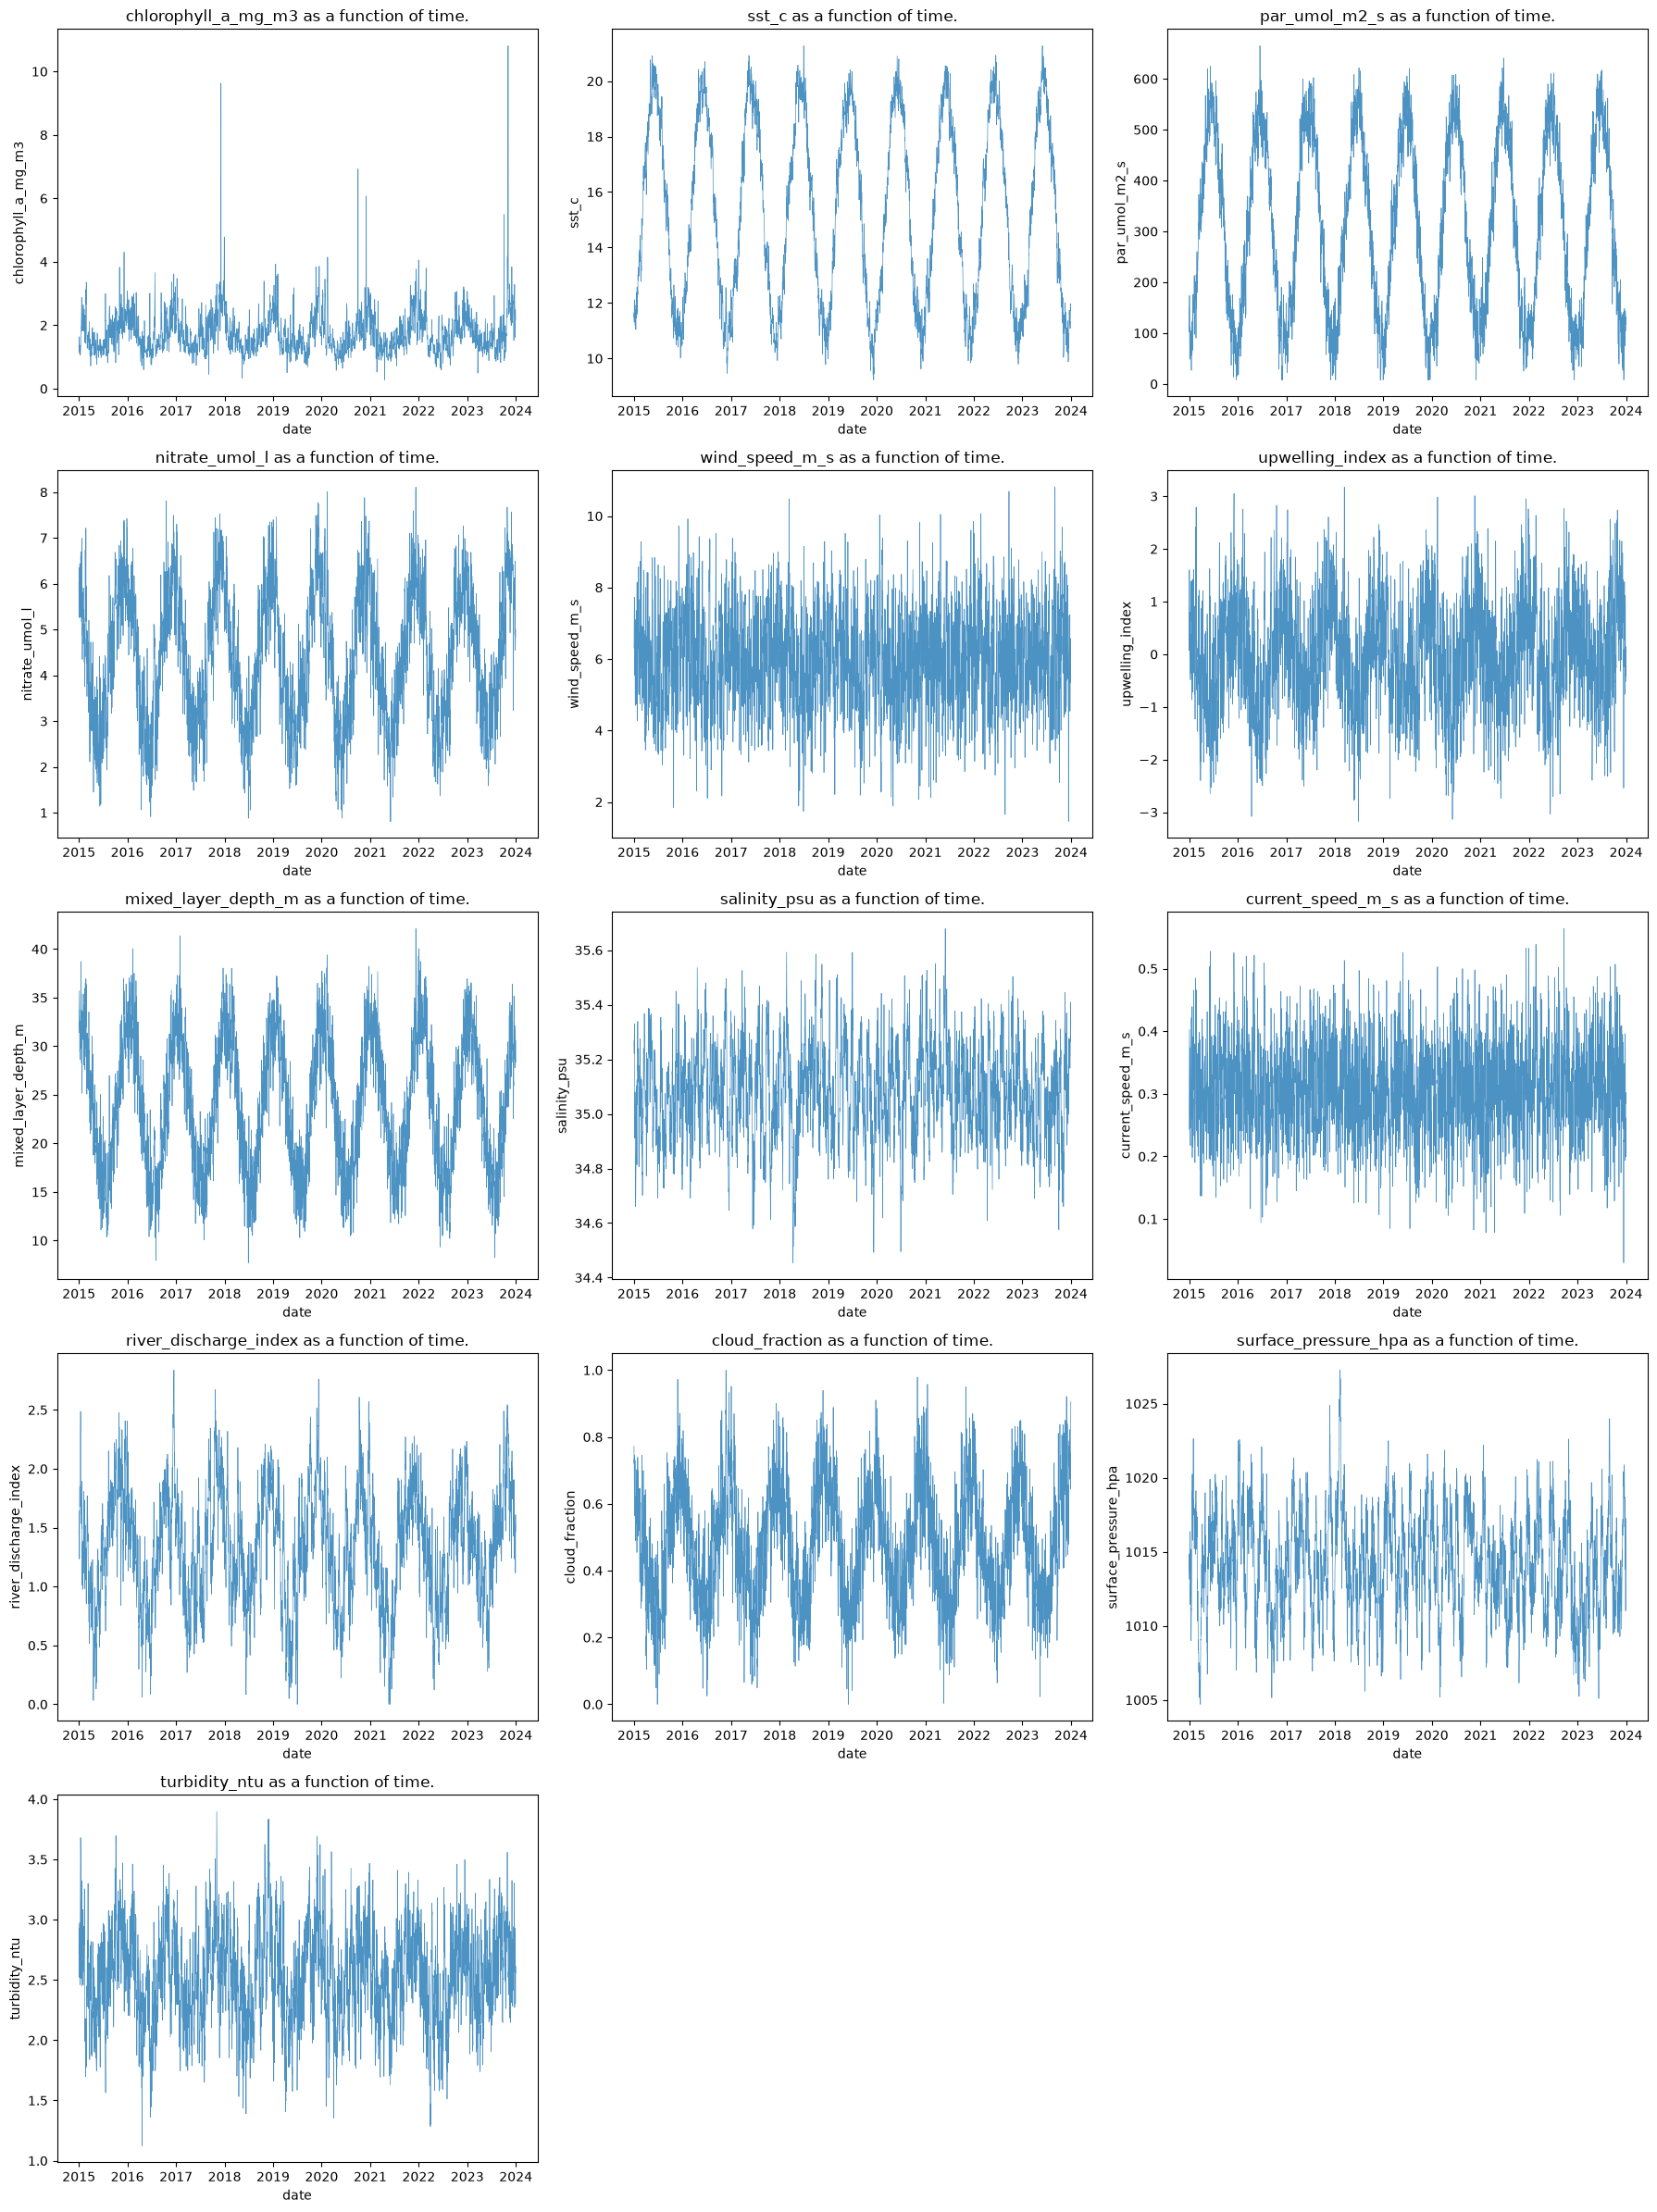

In [66]:
# Load raw data without any transformations
df_raw = pd.read_excel("../../data/chlorophyll_student_2015_2023.xlsx", sheet_name="daily_data")
df_raw["date"] = pd.to_datetime(df_raw["date"])
df_raw = df_raw.sort_values("date").reset_index(drop=True)

time_col = "date"
exogenous_cols = [col for col in df_raw.columns if col not in ["date"]]


plt.figure(figsize=(18, 24))
for i, feature in enumerate(exogenous_cols, 1):
    plt.subplot(5, 3, i)
    plt.plot(df_raw[time_col],df_raw[feature], alpha=0.8, linewidth=0.5)
    
    plt.title(f"{feature} as a function of time.")
    plt.xlabel(time_col)
    plt.ylabel(feature)

plt.tight_layout()
plt.show()


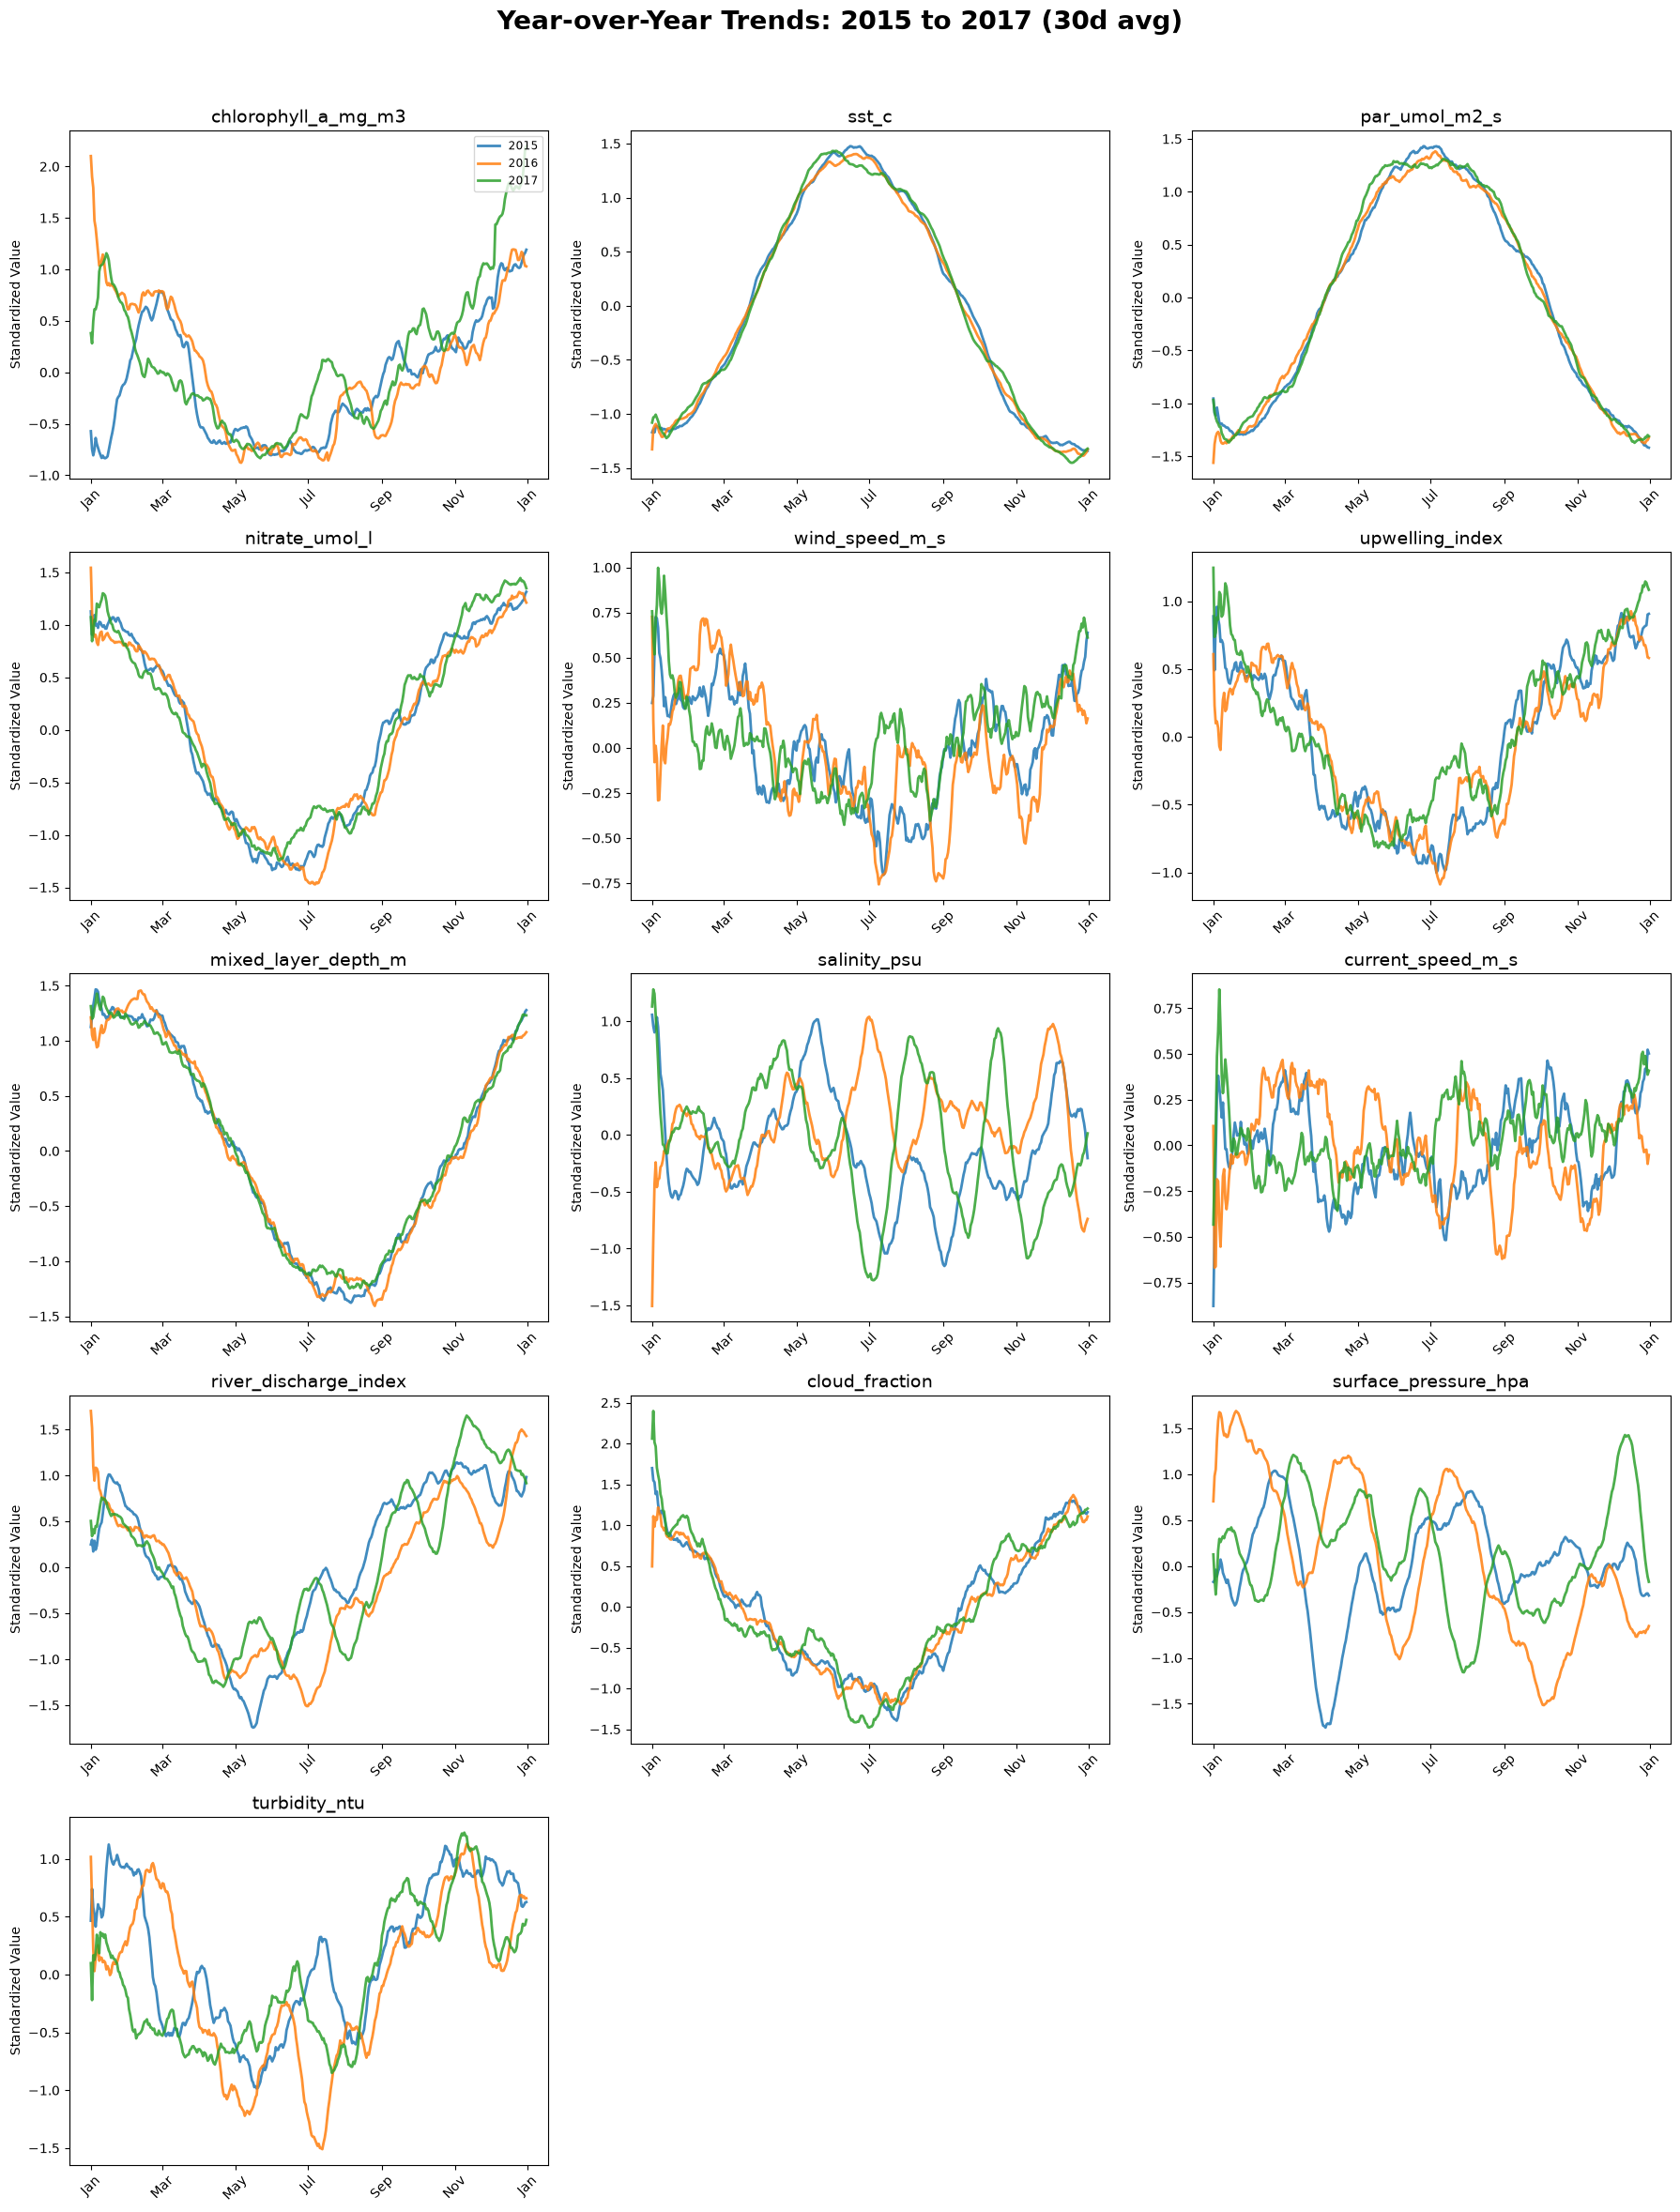

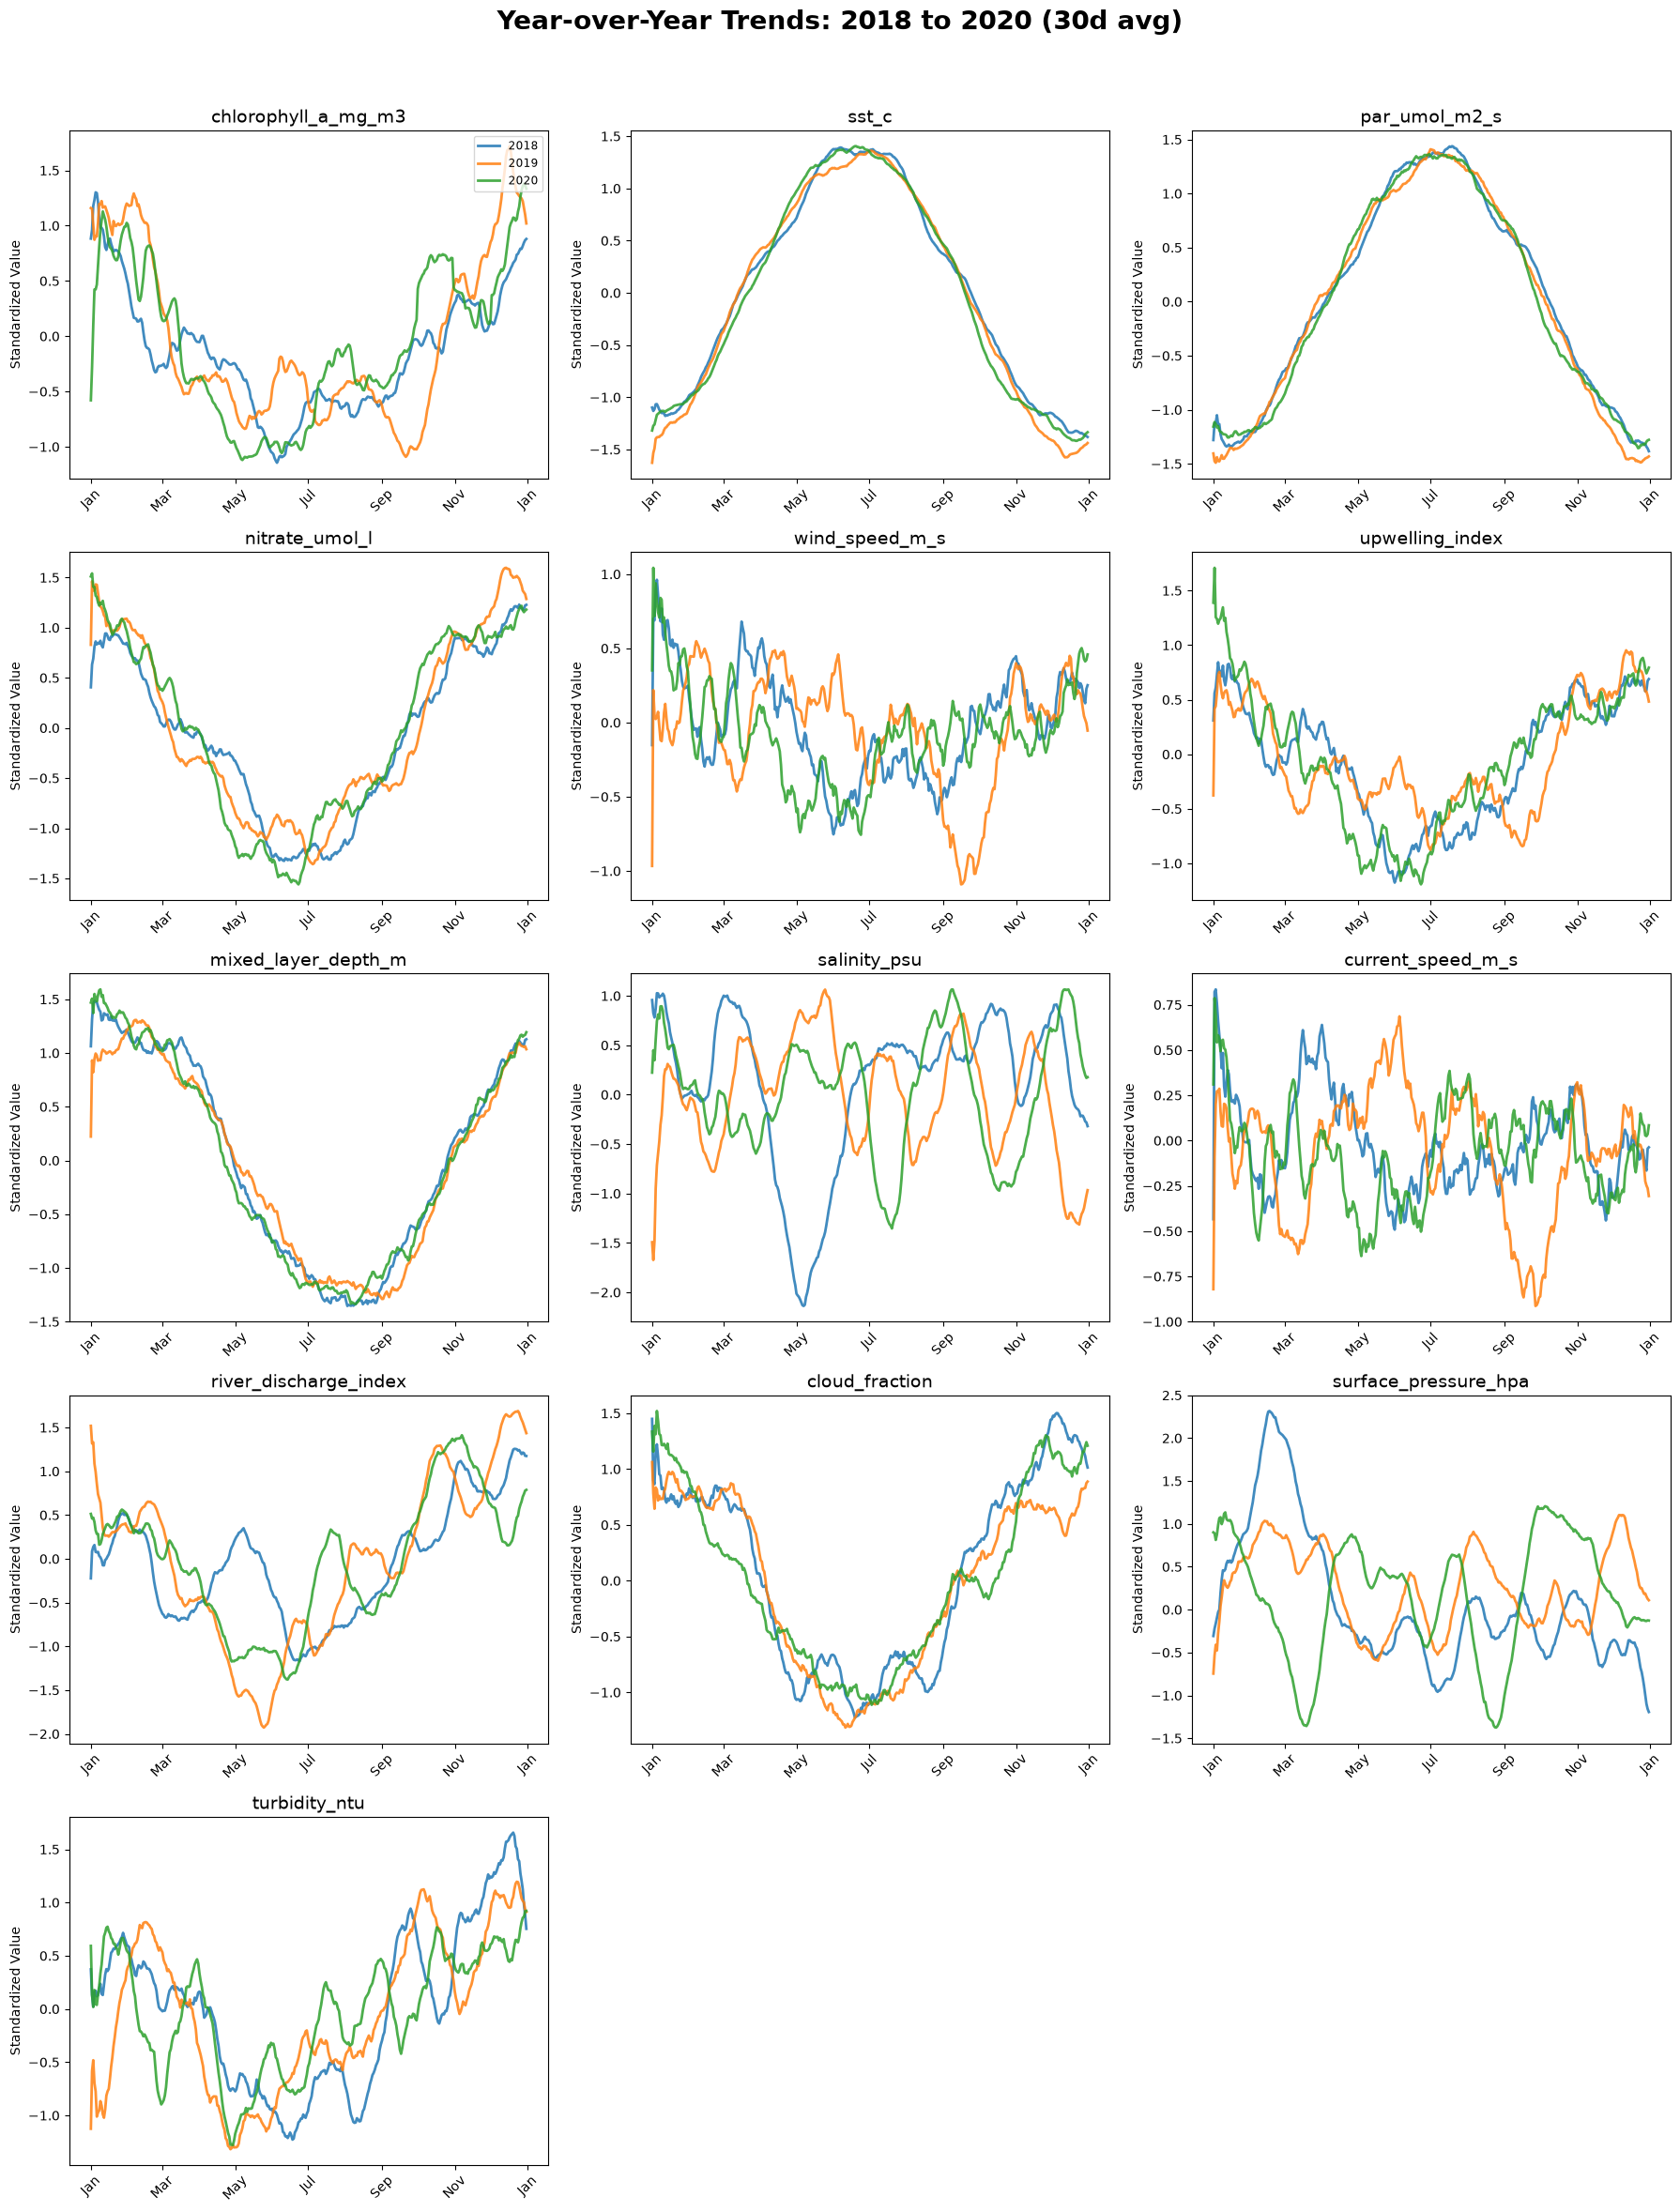

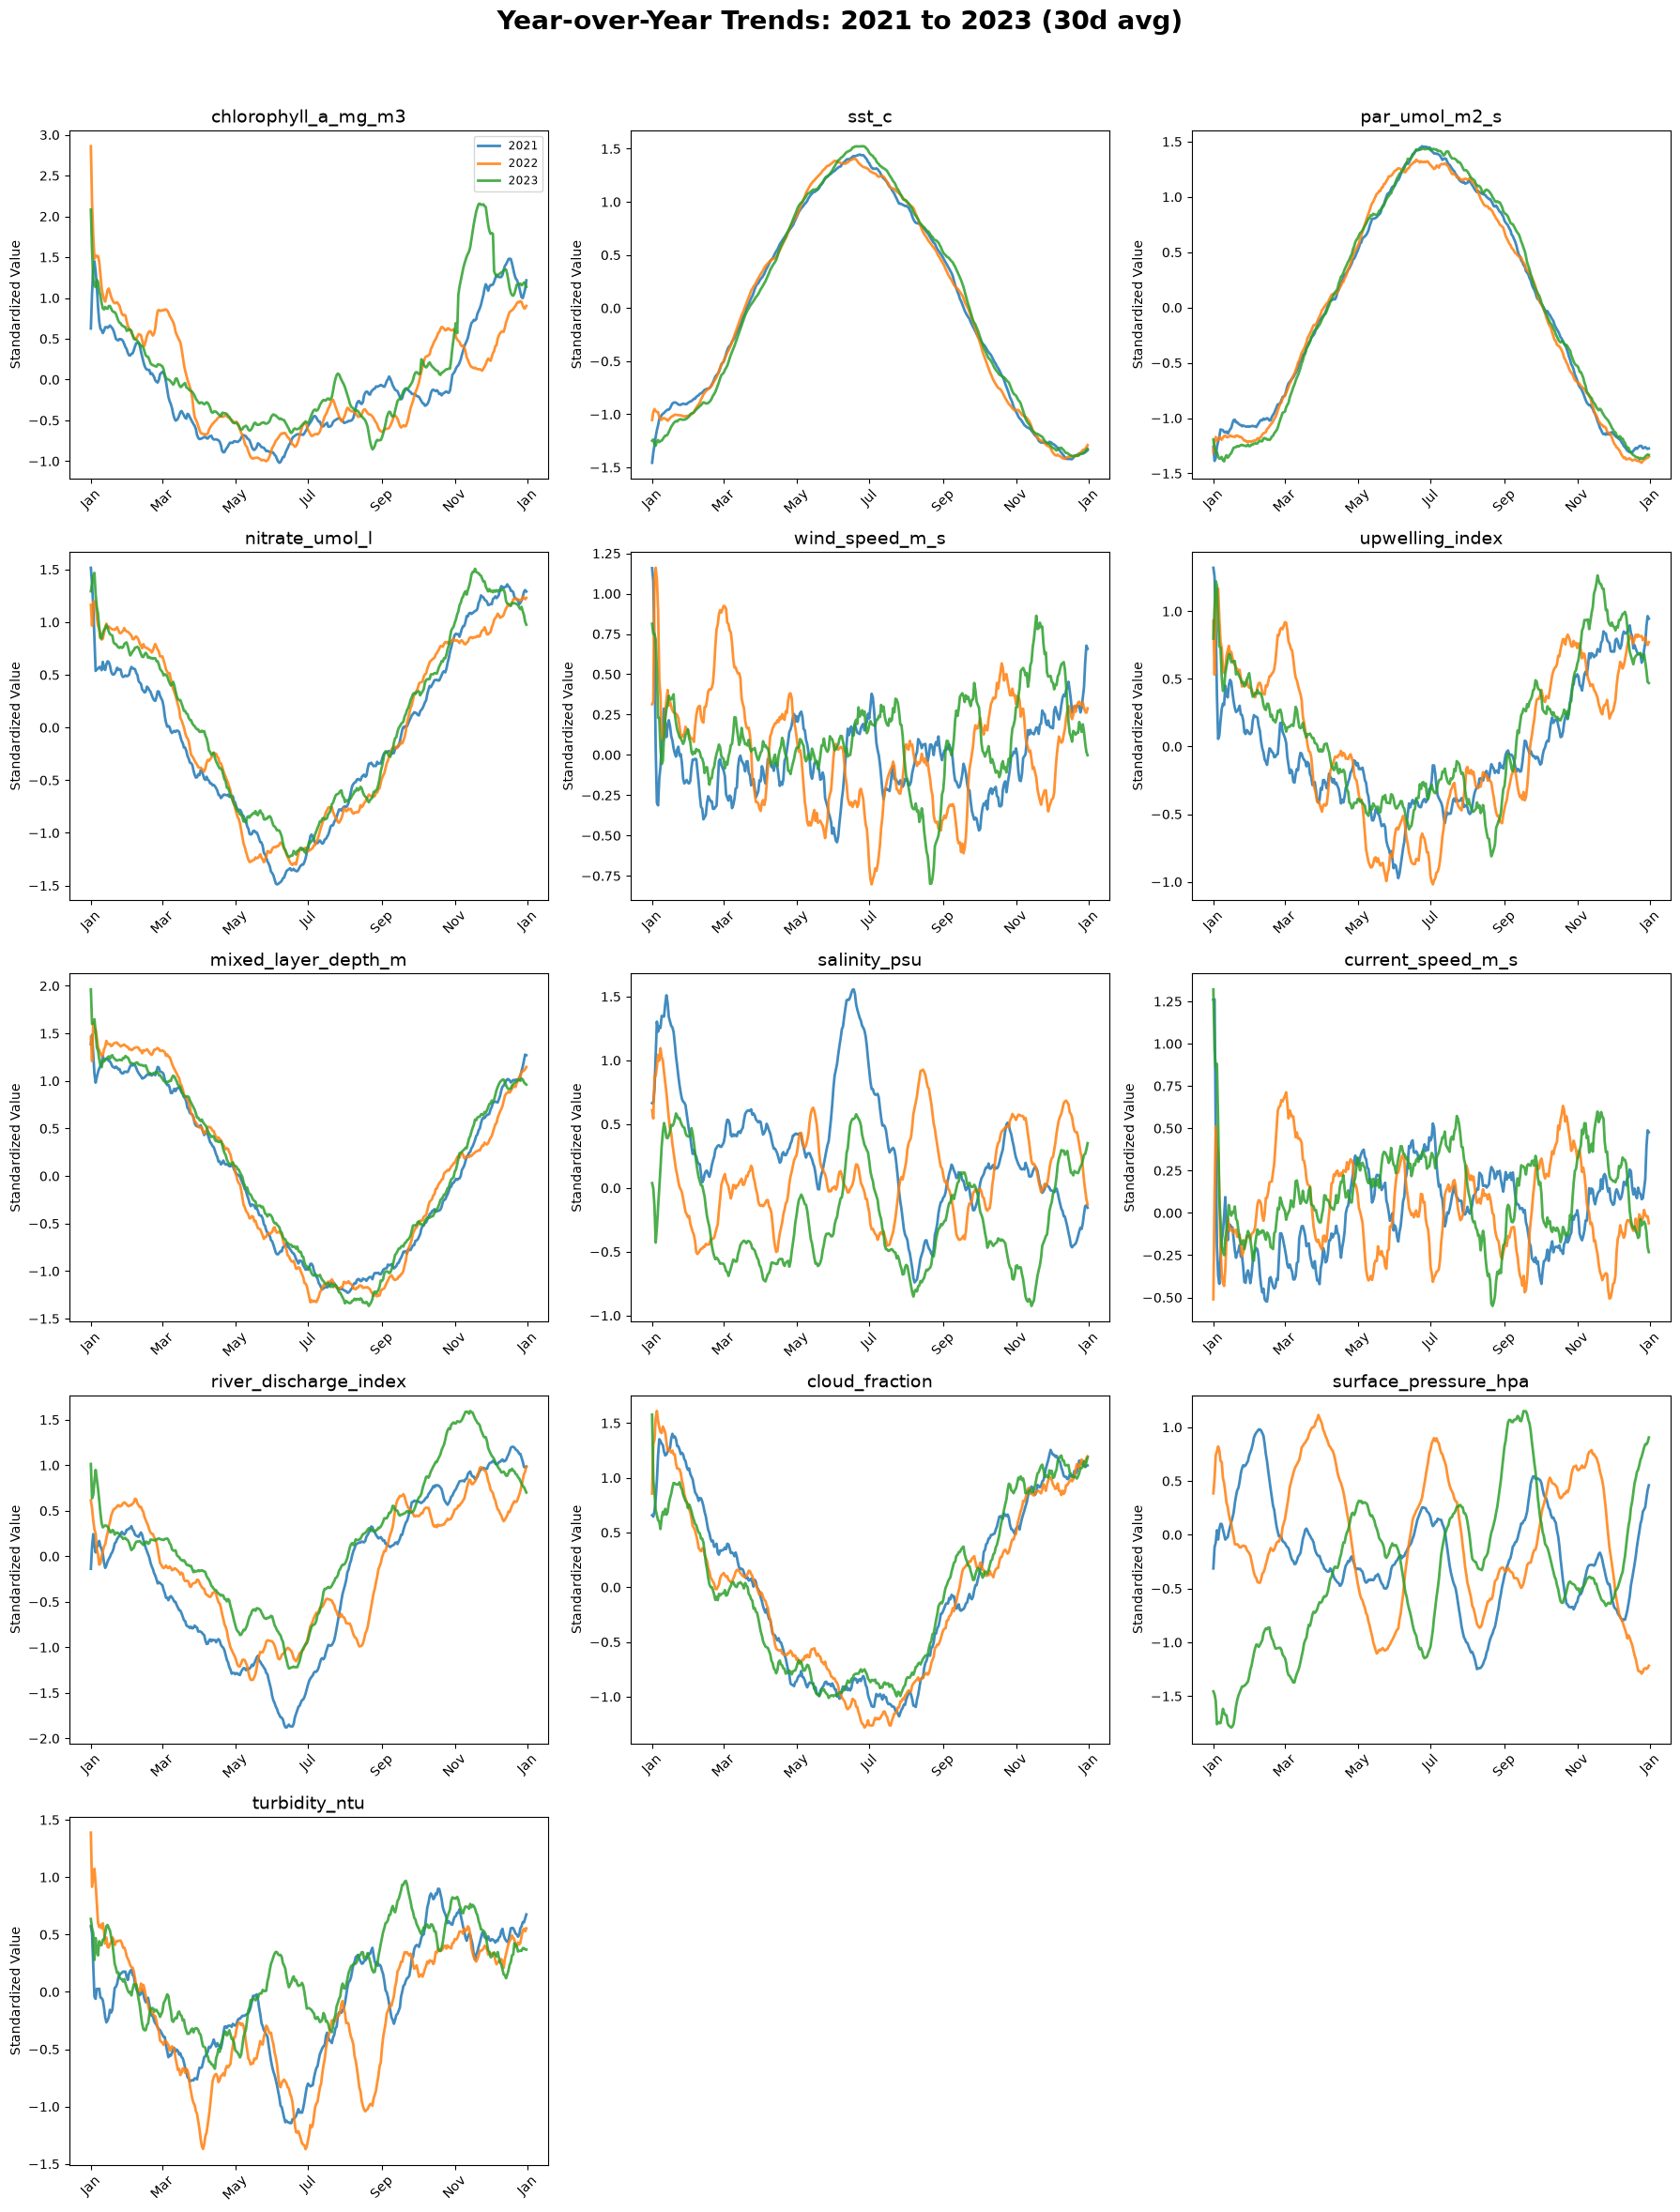

In [86]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.preprocessing import StandardScaler
import numpy as np

# 1. Scale the entire dataset AT ONCE
scaler = StandardScaler()
df_raw[exogenous_cols] = scaler.fit_transform(df_raw[exogenous_cols])

# 2. Setup standard plotting dates and calculate 30-day rolling average
df_raw['year'] = df_raw['date'].dt.year
df_raw['plot_date'] = df_raw['date'].apply(lambda d: d.replace(year=2020))

df_smoothed = df_raw.copy()
for feature in exogenous_cols:
    df_smoothed[feature] = df_raw.groupby('year')[feature].transform(lambda x: x.rolling(window=30, min_periods=1).mean())

# 3. Split the years into chunks of 3 (creates 3 total images for 9 years)
unique_years = sorted(df_smoothed['year'].unique())
year_chunks = [unique_years[i:i + 3] for i in range(0, len(unique_years), 3)]

# 4. Generate one figure per chunk of years
for chunk in year_chunks:
    plt.figure(figsize=(18, 24))
    
    # Format the title to show which years are in this specific image
    title_years = f"{chunk[0]} to {chunk[-1]}" if len(chunk) > 1 else f"{chunk[0]}"
    plt.suptitle(f"Year-over-Year Trends: {title_years} (30d avg)", fontsize=20, fontweight='bold', y=0.98)
    
    for j, feature in enumerate(exogenous_cols, 1):
        plt.subplot(5, 3, j)
        
        # Plot only the 1-3 years assigned to this chunk
        for year in chunk:
            df_year = df_smoothed[df_smoothed['year'] == year]
            plt.plot(df_year['plot_date'], df_year[feature], alpha=0.85, linewidth=2, label=str(year))
        
        plt.title(feature, fontsize=14)
        plt.ylabel("Standardized Value")
        
        plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b'))
        plt.xticks(rotation=45)
        
        if j == 1:
            plt.legend(loc='upper right', fontsize='small')

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

### 3.1 Types of Preprocessing used
During development, we evaluated different combinations of preprocessing steps, tracking flags like `use_log,use_mul,use_sum,use_clip` in our `validation_results.csv` tracking file[cite: 3]. To rigorously prove which data cleaning steps actually improve generalization, we will test all 8 possible combinations of our three primary transformations:

1. **Target Skewness (`use_log`):** Applying `log1p` to Chlorophyll-a.
2. **Outlier Smoothing (`use_smooth`):** Applying a 3-day rolling average to extreme spikes (z-score out of bounds) in both the target and the lagged chlorophyll features.
3. **Hard Clipping (`use_clip`):** Restricting all exogenous features to a `[-3, 3]` standard deviation range.

We iterate through every combination using `itertools.product`. To ensure a fair comparison, all models are evaluated against the exact same **raw, unsmoothed, un-transformed Test set**.

In [83]:
# Create a fresh, unmodified baseline for the ablation study
df_raw = pd.read_excel("../../data/chlorophyll_student_2015_2023.xlsx", sheet_name="daily_data")
df_raw["date"] = pd.to_datetime(df_raw["date"])
df_raw = df_raw.sort_values("date").reset_index(drop=True)

high_limit = 15
low_limit = 0

defined_lags = {
"chlorophyll_a_mg_m3": list(range(1, high_limit)),
"sst_c": list(range(low_limit, high_limit)),
"par_umol_m2_s" : list(range(low_limit,high_limit)), 
"nitrate_umol_l" : list(range(low_limit,high_limit)),
"wind_speed_m_s" : list(range(low_limit,high_limit)),
"upwelling_index" : list(range(low_limit,high_limit)),
"mixed_layer_depth_m" : list(range(low_limit,high_limit)),
"salinity_psu" : list(range(low_limit,high_limit)),
"current_speed_m_s" : list(range(low_limit,high_limit)),
"river_discharge_index" : list(range(low_limit,high_limit)),
"cloud_fraction" : list(range(low_limit,high_limit)),
"surface_pressure_hpa" : list(range(low_limit,high_limit)),
"turbidity_ntu" : list(range(low_limit,high_limit)),
#"nitrate_x_par" : list(range(low_limit,high_limit)),
#"wind_x_upwelling" : list(range(low_limit,high_limit)),
# O Lasso não eliminou algumas destas features mas o R^2 de validação piorou ligeiramente
#"river_div_turbidity" : list(range(low_limit,high_limit)),
#"sst_c_x_nitrate" : list(range(low_limit,high_limit))
#"sst_c": [1, 2, 3],                     # Temperatura de ontem, anteontem e há 3 dias
#"wind_speed_m_s": [1, 7],               # Vento de ontem e da semana passada (exemplo)
# Podes adicionar mais variáveis aqui...
}

df_lagged = build_lagged_frame(df_raw, lag_spec=defined_lags)
X_ablation = df_lagged.drop(columns=[DATE, TARGET])
Y_ablation = df_lagged[TARGET]

# 3-Way Split Indices
lower_sep = -2*365
higher_sep = -365

X_ablation_train = X_ablation.iloc[:lower_sep].copy()
X_ablation_val = X_ablation.iloc[lower_sep:higher_sep].copy()
X_ablation_test = X_ablation.iloc[higher_sep:].copy()

Y_ablation_train_raw = Y_ablation.iloc[:lower_sep].copy()
Y_ablation_val_raw = Y_ablation.iloc[lower_sep:higher_sep].copy()
Y_ablation_test_raw = Y_ablation.iloc[higher_sep:].copy()

# Keep the original validation target for a consistent evaluation.
Y_val_ground_truth = Y_ablation_val_raw.copy()
val_y_zscores = zscore(Y_val_ground_truth)
val_outliers_y = (val_y_zscores < -3) | (val_y_zscores > 3)

Y_val_ground_truth.loc[val_outliers_y] = (
    Y_val_ground_truth
    .rolling(window=3, min_periods=1)
    .mean()
    .shift(1)[val_outliers_y]
)
Y_val_ground_truth = Y_val_ground_truth.ffill().bfill().values

results = []

# WIDENED ALPHA GRID to accommodate both raw and log-scaled target magnitudes
alpha_lasso_defined = np.logspace(-6, 0, 30) 

for use_log, use_smooth, use_clip in itertools.product([True, False], repeat=3):

    X_tr = X_ablation_train.copy()
    X_val = X_ablation_val.copy()
    Y_tr = Y_ablation_train_raw.copy()

    if use_log:
        Y_tr = np.log1p(Y_tr.clip(lower=0))
        chlorophyll_cols = [col for col in X_tr.columns if col.startswith("chlorophyll_a_mg_m3__lag_")]
        X_tr[chlorophyll_cols] = np.log1p(X_tr[chlorophyll_cols].clip(lower=0))
        X_val[chlorophyll_cols] = np.log1p(X_val[chlorophyll_cols].clip(lower=0))

    scaler = StandardScaler()
    X_tr_scaled = pd.DataFrame(scaler.fit_transform(X_tr), columns=X_tr.columns, index=X_tr.index)
    X_val_scaled = pd.DataFrame(scaler.transform(X_val), columns=X_val.columns, index=X_val.index)

    if use_smooth:
        for col in X_tr_scaled.columns:
            if col.startswith("chlorophyll_a_mg_m3__lag_"):
                tr_outliers = X_tr_scaled[col].abs() > 3
                if tr_outliers.any():
                    tr_repl = X_tr_scaled[col].rolling(window=3, min_periods=1).mean().shift(1)
                    X_tr_scaled.loc[tr_outliers, col] = tr_repl[tr_outliers]
                
                val_outliers = X_val_scaled[col].abs() > 3
                if val_outliers.any():
                    val_repl = X_val_scaled[col].rolling(window=3, min_periods=1).mean().shift(1)
                    X_val_scaled.loc[val_outliers, col] = val_repl[val_outliers]

        X_val_scaled = X_val_scaled.ffill().bfill()
        X_tr_scaled = X_tr_scaled.ffill().bfill()
        
        y_train_zscores = zscore(Y_tr)
        train_outliers = (y_train_zscores < -3) | (y_train_zscores > 3)

        if train_outliers.any():
            train_avg_3_above = Y_tr.rolling(window=3, min_periods=1).mean().shift(1)
            Y_tr.loc[train_outliers] = train_avg_3_above[train_outliers]

        Y_tr = Y_tr.ffill().bfill()

    if use_clip:
        X_tr_scaled = X_tr_scaled.clip(-3, 3)
        X_val_scaled = X_val_scaled.clip(-3, 3)
        
    X_tr_scaled = X_tr_scaled.fillna(0)
    X_val_scaled = X_val_scaled.fillna(0)
    Y_tr = Y_tr.fillna(0)

    best_r2 = -float("inf")
    best_alpha = None
    best_mae = None

    for alpha in alpha_lasso_defined:
        model = linear_model.Lasso(alpha=alpha, max_iter=150000)
        model.fit(X_tr_scaled, Y_tr)
        preds = model.predict(X_val_scaled)

        if use_log:
            preds = np.expm1(preds)

        score = r2_score(Y_val_ground_truth, preds)
        mae = mean_absolute_error(Y_val_ground_truth, preds)

        if np.isfinite(score) and score > best_r2:
            best_r2 = score
            best_alpha = alpha
            best_mae = mae
    

    # Construct fresh full-training sets to avoid double-smoothing
    X_full = pd.concat([X_ablation_train, X_ablation_val])
    Y_full = pd.concat([Y_ablation_train_raw, Y_ablation_val_raw])
    X_te = X_ablation_test.copy()
    Y_te_raw = Y_ablation_test_raw.copy()
    
    if use_log:
        Y_full = np.log1p(Y_full.clip(lower=0))
        X_full[chlorophyll_cols] = np.log1p(X_full[chlorophyll_cols].clip(lower=0))
        X_te[chlorophyll_cols] = np.log1p(X_te[chlorophyll_cols].clip(lower=0))

    scaler_final = StandardScaler()
    X_full_scaled = pd.DataFrame(scaler_final.fit_transform(X_full), columns=X_full.columns, index=X_full.index)
    X_te_scaled = pd.DataFrame(scaler_final.transform(X_te), columns=X_te.columns, index=X_te.index)

    if use_smooth:
        for col in X_full_scaled.columns:
            if col.startswith("chlorophyll_a_mg_m3__lag_"):
                full_outliers = X_full_scaled[col].abs() > 3
                if full_outliers.any():
                    full_repl = X_full_scaled[col].rolling(window=3, min_periods=1).mean().shift(1)
                    X_full_scaled.loc[full_outliers, col] = full_repl[full_outliers]
                
                te_outliers = X_te_scaled[col].abs() > 3
                if te_outliers.any():
                    te_repl = X_te_scaled[col].rolling(window=3, min_periods=1).mean().shift(1)
                    X_te_scaled.loc[te_outliers, col] = te_repl[te_outliers]
    
        X_full_scaled = X_full_scaled.ffill().bfill()
        X_te_scaled = X_te_scaled.ffill().bfill()
        
        y_full_zscores = zscore(Y_full)
        full_outliers = (y_full_zscores < -3) | (y_full_zscores > 3)
        if full_outliers.any():
            full_avg_3_above = Y_full.rolling(window=3, min_periods=1).mean().shift(1)
            Y_full.loc[full_outliers] = full_avg_3_above[full_outliers]
            
        Y_full = Y_full.ffill().bfill()

    if use_clip:
        X_full_scaled = X_full_scaled.clip(-3, 3)
        X_te_scaled = X_te_scaled.clip(-3, 3)

    X_full_scaled = X_full_scaled.fillna(0)
    X_te_scaled = X_te_scaled.fillna(0)
    Y_full = Y_full.fillna(0)

    # Retrain completely on Train+Val with optimal validation alpha
    clf_lasso = linear_model.Lasso(alpha=best_alpha, max_iter=150000)
    clf_lasso.fit(X_full_scaled, Y_full)
    predicts_lasso = clf_lasso.predict(X_te_scaled)

    if use_log:
        predicts_lasso = np.expm1(predicts_lasso)

    r2_lasso_test = r2_score(Y_te_raw, predicts_lasso)
    mae_lasso_test = mean_absolute_error(Y_te_raw, predicts_lasso)
    
    results.append({
        "Use Log1p": use_log,
        "Use Smoothing": use_smooth,
        "Use Clipping": use_clip,
        "Best Alpha": best_alpha,
        "Val R^2": best_r2 if best_alpha is not None else np.nan,
        "Val MAE": best_mae if best_alpha is not None else np.nan,
        "Test R^2": r2_lasso_test if best_alpha is not None else np.nan,
        "Test MAE": mae_lasso_test if best_alpha is not None else np.nan
    })

df_ablation_results = (
    pd.DataFrame(results)
    .sort_values(by="Val R^2", ascending=False)
    .reset_index(drop=True)
)

display(df_ablation_results)

,Use Log1p,Use Smoothing,Use Clipping,Best Alpha,Val R^2,Val MAE,Test R^2,Test MAE
0,True,True,False,0.000189,0.838623,0.158677,0.558460,0.193443
1,True,True,True,0.000189,0.838584,0.158550,0.558596,0.193389
2,False,True,True,0.000489,0.836253,0.162078,0.552758,0.201509
3,False,True,False,0.000489,0.836192,0.162250,0.552621,0.200563
4,True,False,False,0.008532,0.832065,0.163585,0.531831,0.206721
5,True,False,True,0.008532,0.831162,0.163822,0.558210,0.199799
6,False,False,False,0.022122,0.826164,0.169661,0.503650,0.218573
7,False,False,True,0.022122,0.825277,0.169122,0.558396,0.205854


## 4. Discarded Experiments: Interactions and Over-Engineering

During the development phase, we hypothesized that non-linear feature interactions (e.g., wind speed multiplying with sea surface temperature) might capture complex ocean dynamics better.

We generated second-order interaction terms using `itertools.combinations_with_replacement` across all lagged features. However, this exploded our dimensionality to thousands of sparse features, leading to massive overfitting and degrading the validation $R^2$ score. We also tested native `ElasticNet` implementations, but found a sequential Lasso-to-Ridge pipeline much more interpretable. 

*The code below is preserved for documentation but kept commented out.*

In [ ]:
# [DEPRECATED] Second-order interaction features
"""
raw_columns_names = [f"{col}__lag_0" for col in df_raw.drop(columns=["date", "chlorophyll_a_mg_m3"]).columns]
raw_columns_names.append("chlorophyll_a_mg_m3__lag_1")

new_columns = {}
for name, name2 in itertools.combinations_with_replacement(raw_columns_names, 2):
    new_columns[f"row_mul_{name}_{name2}"] = X_train_scaled[f"{name}"] * X_train_scaled[f"{name2}"]

df_new_features = pd.DataFrame(new_columns)
X_experimental = pd.concat([X_train_scaled, df_new_features], axis=1)

# Training a model on X_experimental resulted in severe overfitting.
"""
print("Interaction term generation skipped to maintain generalized performance.")

Interaction term generation skipped to maintain generalized performance.


## 5. Final Architecture: Lasso Selection + Ridge Regression

Our final modeling strategy leverages the strengths of two different regularization techniques:

1.  **Lasso ($L_1$ Penalty):** Used strictly as a feature selector. We run a log-space grid search to find the optimal alpha. Lasso aggressively pushes the coefficients of unhelpful features to exactly $0.0$.
2.  **Masking:** We extract the boolean mask of features that survived the Lasso penalty.
3.  **Ridge ($L_2$ Penalty):** We train a Ridge regression model exclusively on the surviving features. This mitigates the multicollinearity among the remaining highly-correlated environmental lags without arbitrarily dropping them.

Lasso selection retained 128 out of 196 features.
Final Validation R^2 (Ridge after Lasso): -0.9045
Final Validation MAE: 4.6937 mg/m3


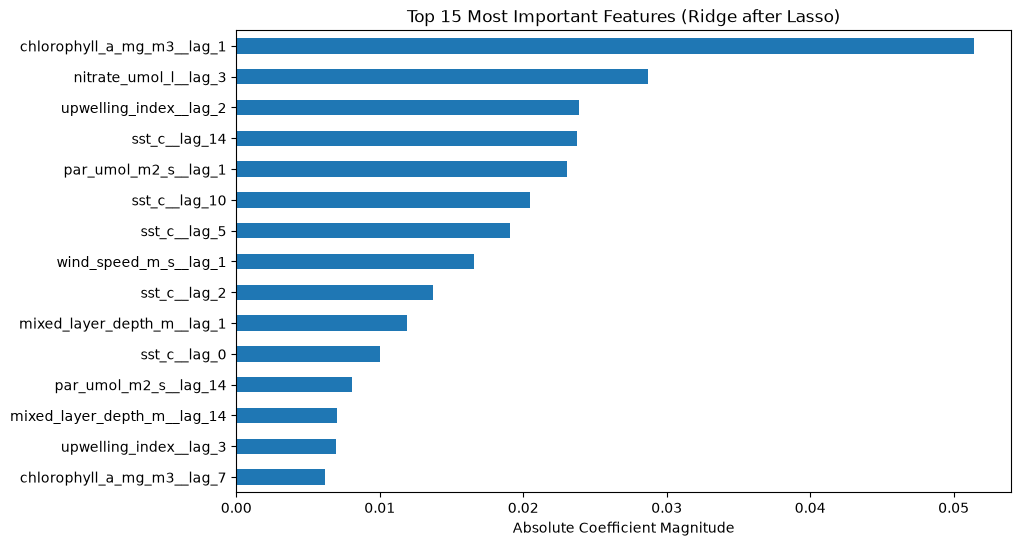

In [ ]:
# 1. Lasso for Feature Selection
alpha_lasso_defined = np.logspace(-4, -2, 20)
best_r2_lasso = -float('inf')  
best_alpha_lasso = None

# Transform validation target back to original scale for true metric calculation
Y_val_true = np.expm1(Y_val)

for alpha in alpha_lasso_defined:
    clf_lasso = linear_model.Lasso(alpha=alpha, max_iter=150000)
    clf_lasso.fit(X_train_scaled, Y_train)
    
    predicts_lasso = np.expm1(clf_lasso.predict(X_val_scaled))
    r2_lasso = r2_score(Y_val_true, predicts_lasso)

    if r2_lasso > best_r2_lasso:
        best_r2_lasso = r2_lasso
        best_alpha_lasso = alpha
        coefficients_lasso = pd.Series(clf_lasso.coef_, index=X_train_scaled.columns)

# 2. Extract Kept Features
kept_features_lasso = coefficients_lasso != 0.0
X_train_cut = X_train_scaled.loc[:, kept_features_lasso]
X_val_cut = X_val_scaled.loc[:, kept_features_lasso]

print(f"Lasso selection retained {kept_features_lasso.sum()} out of {len(kept_features_lasso)} features.")

# 3. Ridge on Selected Features
alpha_ridge_defined = np.linspace(1e-16, 1e-15, 20)
best_r2_ridge_lasso = -float('inf')  
best_alpha_ridge_lasso = None

for alpha in alpha_ridge_defined:
    clf_ridge = linear_model.Ridge(alpha=alpha)
    clf_ridge.fit(X_train_cut, Y_train)

    predicts_ridge_lasso = np.expm1(clf_ridge.predict(X_val_cut))
    r2_ridge_lasso = r2_score(Y_val_true, predicts_ridge_lasso)

    if r2_ridge_lasso > best_r2_ridge_lasso:
        best_r2_ridge_lasso = r2_ridge_lasso
        best_alpha_ridge_lasso = alpha
        mae_best_ridge_lasso = mean_absolute_error(Y_val_true, predicts_ridge_lasso)
        coefficients_ridge_lasso = pd.Series(clf_ridge.coef_, index=X_train_cut.columns)

print(f"Final Validation R^2 (Ridge after Lasso): {best_r2_ridge_lasso:.4f}")
print(f"Final Validation MAE: {mae_best_ridge_lasso:.4f} mg/m3")

# Plot Top Features
importance_ridge_lasso = coefficients_ridge_lasso.abs().sort_values(ascending=False).head(15)
plt.figure(figsize=(10, 6))
importance_ridge_lasso.plot(kind='barh')
plt.title("Top 15 Most Important Features (Ridge after Lasso)")
plt.gca().invert_yaxis()
plt.xlabel("Absolute Coefficient Magnitude")
plt.show()

In [ ]:
# ==============================================================================
# Cross-Validation, Model Selection, Testing, and Serialization
# ==============================================================================

Y = df_lagged["chlorophyll_a_mg_m3"]
X = df_lagged.drop(columns=["date", "chlorophyll_a_mg_m3"], errors="ignore")

# Last year of all is the final test
test_size = 365

# cv refers to cross validation
X_cv, X_test = X.iloc[:-test_size].copy(), X.iloc[-test_size:].copy()
Y_cv, Y_test = Y.iloc[:-test_size].copy(), Y.iloc[-test_size:].copy()

# Creats 4 different temporal windows for the cross validation
tscv = TimeSeriesSplit(n_splits=4) 

vector_length_lasso = 50
vector_length_ridge = 50
alpha_lasso_defined = np.logspace(-4, -2, vector_length_lasso)
alpha_ridge_defined = np.logspace(-2, 4, vector_length_ridge)

# ------------------------------------------------------------------------------
# 1. Optimize Lasso using TimeSeries Cross Validation
# ------------------------------------------------------------------------------
best_r2_lasso = -float('inf')
best_alpha_lasso = None

for alpha in alpha_lasso_defined:
    vector_r2_scores = []

    for train_index, val_index in tscv.split(X_cv):
        X_train_fold, X_val_fold = X_cv.iloc[train_index].copy(), X_cv.iloc[val_index].copy()
        Y_train_fold, Y_val_fold = Y_cv.iloc[train_index].copy(), Y_cv.iloc[val_index].copy()
        
        # Scaling the train data
        scaler = StandardScaler()
        X_train_fold_scaled = pd.DataFrame(scaler.fit_transform(X_train_fold), columns=X_train_fold.columns)
        X_val_fold_scaled = pd.DataFrame(scaler.transform(X_val_fold), columns=X_val_fold.columns)
        
        # Clipping the outliers for both test and validation data
        for col in X_train_fold_scaled.columns:
            if col.startswith("chlorophyll_a_mg_m3__lag_"):
                continue  
            X_train_fold_scaled[col] = X_train_fold_scaled[col].clip(-3, 3)
            X_val_fold_scaled[col] = X_val_fold_scaled[col].clip(-3, 3)
        
        clf_lasso = linear_model.Lasso(alpha=alpha, max_iter=150000)
        clf_lasso.fit(X_train_fold_scaled, Y_train_fold)
        
        # Predict and revert log to evaluate in real mg/m3
        preds_lasso_mg = np.expm1(clf_lasso.predict(X_val_fold_scaled))
        Y_val_fold_mg = np.expm1(Y_val_fold)
        
        vector_r2_scores.append(r2_score(Y_val_fold_mg, preds_lasso_mg))

    mean_r2 = np.mean(vector_r2_scores) 

    if mean_r2 > best_r2_lasso:
        best_r2_lasso = mean_r2
        best_alpha_lasso = alpha

print(f"Best Lasso (CV) alpha={best_alpha_lasso} with mean R2 of {best_r2_lasso:.4f}")

# Train on the full CV set to extract the best kept features
scaler_cv = StandardScaler()
X_cv_scaled = pd.DataFrame(scaler_cv.fit_transform(X_cv), columns=X_cv.columns).clip(-3, 3)

final_cv_lasso = linear_model.Lasso(alpha=best_alpha_lasso, max_iter=150000)
final_cv_lasso.fit(X_cv_scaled, Y_cv)

preds_lasso_cv_mg = np.expm1(final_cv_lasso.predict(X_cv_scaled))
mae_best_lasso = mean_absolute_error(np.expm1(Y_cv), preds_lasso_cv_mg)
coefficients_lasso = pd.Series(final_cv_lasso.coef_, index=X_cv_scaled.columns)
kept_features_lasso = coefficients_lasso[coefficients_lasso != 0.0].index.tolist()

# ------------------------------------------------------------------------------
# 2. Optimize Ridge on features kept by Lasso
# ------------------------------------------------------------------------------
X_cv_cut = X_cv.loc[:, kept_features_lasso]

best_r2_ridge_lasso = -float('inf')  
best_alpha_ridge_lasso = None

for alpha in alpha_ridge_defined:
    fold_r2_scores = []
    
    for train_index, val_index in tscv.split(X_cv_cut):
        X_train_fold, X_val_fold = X_cv_cut.iloc[train_index].copy(), X_cv_cut.iloc[val_index].copy()
        Y_train_fold, Y_val_fold = Y_cv.iloc[train_index].copy(), Y_cv.iloc[val_index].copy()
        
        scaler = StandardScaler()
        X_train_fold_scaled = pd.DataFrame(scaler.fit_transform(X_train_fold), columns=X_train_fold.columns)
        X_val_fold_scaled = pd.DataFrame(scaler.transform(X_val_fold), columns=X_val_fold.columns)

        for col in X_train_fold_scaled.columns:
            if col.startswith("chlorophyll_a_mg_m3__lag_"):
                continue  
            X_train_fold_scaled[col] = X_train_fold_scaled[col].clip(-3, 3)
            X_val_fold_scaled[col] = X_val_fold_scaled[col].clip(-3, 3)
                    
        clf_ridge = linear_model.Ridge(alpha=alpha)
        clf_ridge.fit(X_train_fold_scaled, Y_train_fold)
        
        preds_ridge_mg = np.expm1(clf_ridge.predict(X_val_fold_scaled))
        Y_val_fold_mg = np.expm1(Y_val_fold)
        fold_r2_scores.append(r2_score(Y_val_fold_mg, preds_ridge_mg))
        
    mean_r2 = np.mean(fold_r2_scores)
    if mean_r2 > best_r2_ridge_lasso:
        best_r2_ridge_lasso = mean_r2
        best_alpha_ridge_lasso = alpha

# Train final Ridge CV
X_cv_cut_scaled = pd.DataFrame(scaler_cv.fit_transform(X_cv_cut), columns=X_cv_cut.columns).clip(-3, 3)
final_cv_ridge = linear_model.Ridge(alpha=best_alpha_ridge_lasso)
final_cv_ridge.fit(X_cv_cut_scaled, Y_cv)

preds_ridge_cv_mg = np.expm1(final_cv_ridge.predict(X_cv_cut_scaled))
mae_best_ridge_lasso = mean_absolute_error(np.expm1(Y_cv), preds_ridge_cv_mg)
coefficients_ridge_lasso = pd.Series(final_cv_ridge.coef_, index=X_cv_cut_scaled.columns)

# ------------------------------------------------------------------------------
# 3. Final Testing Set Evaluation
# ------------------------------------------------------------------------------
scaler_final = StandardScaler()
X_cv_scaled_final = pd.DataFrame(scaler_final.fit_transform(X_cv), columns=X_cv.columns).clip(-3, 3)
X_test_scaled = pd.DataFrame(scaler_final.transform(X_test), columns=X_test.columns).clip(-3, 3)

# Retrain Lasso on complete history
clf_lasso_test = linear_model.Lasso(alpha=best_alpha_lasso, max_iter=150000)
clf_lasso_test.fit(X_cv_scaled_final, Y_cv)
predicts_lasso_test = np.expm1(clf_lasso_test.predict(X_test_scaled))

r2_lasso_test = r2_score(np.expm1(Y_test), predicts_lasso_test)
mae_lasso_test = mean_absolute_error(np.expm1(Y_test), predicts_lasso_test)

# Retrain Ridge-Lasso on complete history
X_cv_cut_final = X_cv_scaled_final.loc[:, kept_features_lasso]
X_test_cut_final = X_test_scaled.loc[:, kept_features_lasso]

clf_ridge_test = linear_model.Ridge(alpha=best_alpha_ridge_lasso, max_iter=150000)
clf_ridge_test.fit(X_cv_cut_final, Y_cv)
predicts_ridge_lasso_test = np.expm1(clf_ridge_test.predict(X_test_cut_final))

r2_ridge_lasso_test = r2_score(np.expm1(Y_test), predicts_ridge_lasso_test)
mae_ridge_lasso_test = mean_absolute_error(np.expm1(Y_test), predicts_ridge_lasso_test)

# Print Detailed Outputs
print("\n---- Validation Results ----")
print(f"\n[Lasso]")
print(f"Alpha Best: {best_alpha_lasso}")
print(f"Validation R² Best: {best_r2_lasso:.4f}")
print(f"Validation MAE Best: {mae_best_lasso:.4f} mg/m3")

print(f"\n[Ridge-Lasso]")
print(f"Alpha Best: {best_alpha_ridge_lasso}")
print(f"Validation R² Best: {best_r2_ridge_lasso:.4f}")
print(f"Validation MAE Best: {mae_best_ridge_lasso:.4f} mg/m3")
print("\n--- Top 20 Most Important Features ---")
print(coefficients_ridge_lasso.abs().sort_values(ascending=False).head(20))

print("\n---- Final Test Set Results ----")
print(f"[Lasso] Test R²: {r2_lasso_test:.4f} | Test MAE: {mae_lasso_test:.4f} mg/m3")
print(f"[Ridge-Lasso] Test R²: {r2_ridge_lasso_test:.4f} | Test MAE: {mae_ridge_lasso_test:.4f} mg/m3")

# ------------------------------------------------------------------------------
# 4. Plotting Test Predictions vs Real (Static to comply with user context)
# ------------------------------------------------------------------------------
Y_test_real = np.expm1(Y_test)

plt.figure(figsize=(14, 6))
# Subplot 1: Timeline comparison
plt.subplot(1, 2, 1)
plt.plot(Y_test_real.values, label='Real Values', color='tab:blue', alpha=0.7)
plt.plot(predicts_ridge_lasso_test, label='Predictions (Ridge-Lasso)', color='tab:orange', alpha=0.7)
plt.title("Test Set: Real vs Predicted (Timeline)")
plt.xlabel("Days in Test Set")
plt.ylabel("Chlorophyll a (mg/m3)")
plt.legend()

# Subplot 2: Scatter correlation
plt.subplot(1, 2, 2)
plt.scatter(Y_test_real.values, predicts_ridge_lasso_test, alpha=0.5, color='tab:green', s=15)
max_val = max(Y_test_real.max(), predicts_ridge_lasso_test.max())
min_val = min(Y_test_real.min(), predicts_ridge_lasso_test.min())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', label='Ideal Fit (y=x)')
plt.title(f"Test Set Correlation (R² = {r2_ridge_lasso_test:.2f})")
plt.xlabel("Real Chlorophyll a (mg/m3)")
plt.ylabel("Predicted Chlorophyll a (mg/m3)")
plt.legend()

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 5. Full Dataset Refitting and Serialization
# ------------------------------------------------------------------------------
X_total = pd.concat([X_cv, X_test])
Y_total = pd.concat([Y_cv, Y_test])

scaler_final = StandardScaler()
X_final_scaled = pd.DataFrame(scaler_final.fit_transform(X_total), columns=X_total.columns).clip(-3, 3)

lasso_final = linear_model.Lasso(alpha=best_alpha_lasso, max_iter=150000)
lasso_final.fit(X_final_scaled, Y_total)

coefficients_final = pd.Series(lasso_final.coef_, index=X_final_scaled.columns)
kept_features_final = coefficients_final[coefficients_final != 0.0].index.tolist()

X_final_cut = X_final_scaled.loc[:, kept_features_final]
ridge_final = linear_model.Ridge(alpha=best_alpha_ridge_lasso, max_iter=150000)
ridge_final.fit(X_final_cut, Y_total)

# Serialize final artifact
model_artifact = {
    "scaler": scaler_final,
    "kept_features": kept_features_final,
    "model": ridge_final
} 

output_path = Path("../best_model/model.pkl")
output_path.parent.mkdir(parents=True, exist_ok=True)

with open(output_path, "wb") as f:
    pickle.dump(model_artifact, f)

print(f"\nFinal model successfully saved to {output_path}")

NameError: name 'df_lagged' is not defined